# Phase 5: Injury analysis (pattern evaluation)

**Question:** do players in teams with different playing styles get injured differently: how often, how badly
(days lost) and where on the body; and how does this change over seasons and differ between leagues?

**Unit:** the **player-club-season** (Phase 2 membership: ≥ 1 appearance or marked injured), with its team's style
(Phase 4, k = 7; k = 4 as a check). Injuries are those lasting more than 7 days (Phase 2).

**Methods** (descriptive, as the course allows):
- **Rates:** injuries per player-season, injuries per 1,000 minutes, days lost per player-season, share severe.
- **League-adjusted rate ratio (RR):** Transfermarkt records injuries at very different rates per league, so each
  group's injuries are compared with what its players would have at their **league's average rate** (indirect
  standardisation): RR = observed / expected. RR 1.2 = 20% more than the league average. A stricter version uses
  the average of league × age band × position.
- **95% confidence intervals:** bootstrap over **team-seasons** (players of one squad share coaches, medical staff
  and schedule, so they are not independent), 1,000 resamples, fixed seed.
- **Tests:** chi-square for the body-area mix (with Cramér's V as effect size) and for observed vs expected injuries.

**Steps**
1. Player-season table
2. Rate and bootstrap helpers; league baselines
3. Injury frequency and days lost by style
4. Body areas by style
5. Seasons: injury trend and style shares over time
6. Leagues: rates, body areas, style effect within each league
7. Age and position: is it the squad mix?
8. Team strength and workload
9. Fitness absences (secondary outcome)
10. Sensitivity checks
12. Style cards: what each style looks like on the pitch
13. Core teams only
14. How the ways of playing changed, and in what shape
15. How teams move between styles
16. Style mix and injuries per era
17. How much of the injury trend comes from styles changing (decomposition)
18. Style dimensions vs injury outcomes across league-seasons
19. One story per league
20. Report

**Inputs:** `data/02_injuries/`, `data/03_features/`, `data/04_clusters/`, `tm_squads`, `us_team_matches`.
**Outputs:** `data/05_injury_analysis/`, `reports/05_injury_analysis.md`, `reports/figures/05_*.png`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2, chi2_contingency

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, SEASONS, phase_dir
from analysis.load import league_from_understat, read_table, season_key
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

PHASE = "05_injury_analysis"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
N_BOOT = 1000
AGE_BANDS = [0, 21, 25, 29, 99]  # ≤ 21, 22–25, 26–29, 30+ (age on 1 January of the season)
AGE_LABELS = ["≤21", "22–25", "26–29", "30+"]
COVID_SEASONS = ["2019-20", "2020-21"]
LEAGUES = ["Premier League", "La Liga", "Serie A", "Bundesliga", "Ligue 1"]

# Chart palette: validated reference palette (dataviz skill), categorical slots in fixed order by style.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#f0efec", "#86b6ef", "#2a78d6", "#104281"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name

## Step 1. Player-season table

One row per player-club-season with: league, season, club, team style (k = 7 and k = 4), team strength (points per
match), team workload (Phase 3 exposure features), the player's age band and position, minutes in all competitions,
and his injuries at that club that season (count, days lost, severe, by body area, with surgery), plus mild injuries
(4–7 days) and fitness absences for the sensitivity check and the secondary outcome.

In [2]:
members = pd.read_parquet(DATA_DIR / "02_injuries" / "player_club_seasons.parquet")
injuries = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_clean.parquet")
mild = pd.read_parquet(DATA_DIR / "02_injuries" / "injuries_mild.parquet")
non_inj = pd.read_parquet(DATA_DIR / "02_injuries" / "non_injuries.parquet")
clusters = pd.read_parquet(DATA_DIR / "04_clusters" / "team_season_clusters.parquet").rename(columns={"tm_club_id": "club_id"})
features = pd.read_parquet(DATA_DIR / "03_features" / "team_season_features.parquet").rename(columns={"tm_club_id": "club_id"})
roles = pd.read_csv(DATA_DIR / "03_features" / "feature_roles.csv")
EXPOSURE = roles[(roles.role == "exposure") & (roles.status == "kept")].feature.tolist()

# Team strength: league points per match (Understat).
um = read_table("us_team_matches")
points = (um.assign(league=um.league.map(league_from_understat), season=um.season.astype(int), pts=um.pts.astype(float))
          .groupby(["league", "season", "team_id"]).pts.mean().rename("points_pm").reset_index().rename(columns={"team_id": "us_team_id"}))
keys = pd.read_csv(DATA_DIR / "01_entities" / "team_seasons.csv", dtype={"tm_club_id": str, "us_team_id": str}).rename(columns={"tm_club_id": "club_id"})
team = (clusters.merge(keys[["league", "season", "club_id", "us_team_id"]], on=["league", "season", "club_id"])
        .merge(points, on=["league", "season", "us_team_id"]).merge(features[["league", "season", "club_id"] + EXPOSURE], on=["league", "season", "club_id"]))
team["strength"] = pd.qcut(team.points_pm, 3, labels=["weaker third", "middle third", "stronger third"])
assert len(team) == 1170

# Player attributes: position (constant per player) and age on 1 January of the season.
sq = read_table("tm_squads")
player = sq[["playerId", "position_group", "date_of_birth"]].replace("", np.nan).groupby("playerId").first()
ps = members.merge(team.drop(columns=["club", "season_key", "us_team_id"]), on=["league", "season", "club_id"], how="left")
ps = ps.join(player, on="playerId")
dob = pd.to_datetime(ps.date_of_birth, errors="coerce")
ps["age"] = ((pd.to_datetime((ps.season + 1).astype(str) + "-01-01") - dob).dt.days / 365.25).round(1)
ps["age_band"] = pd.cut(ps.age, AGE_BANDS, labels=AGE_LABELS)
ps["position"] = ps.position_group.str.title()

# Injuries per player-club-season.
KEY = ["playerId", "club_id", "season"]
inj = injuries.assign(severe=injuries.severity.str.startswith("severe"), surgery=injuries.surgery.astype(bool))
agg = inj.groupby(KEY).agg(injuries=("days", "size"), days_lost=("days", "sum"), severe=("severe", "sum"), surgeries=("surgery", "sum"))
areas = pd.crosstab([inj.playerId, inj.club_id, inj.season], inj.body_area).add_prefix("area: ")
mild_n = mild.groupby(KEY).size().rename("mild_injuries")
fit_n = non_inj[non_inj.non_injury_reason == "fitness"].groupby(KEY).size().rename("fitness_absences")
ps = ps.join(agg, on=KEY).join(areas, on=KEY).join(mild_n, on=KEY).join(fit_n, on=KEY)
count_cols = ["injuries", "days_lost", "severe", "surgeries", "mild_injuries", "fitness_absences"] + list(areas.columns)
ps[count_cols] = ps[count_cols].fillna(0).astype(int)
ps["team_season"] = ps.league + " " + ps.season_key + " " + ps.club_id

# Checks: every injury lands on exactly one player-season; every player-season has a style.
assert ps.cluster_name.notna().all()
assert ps.injuries.sum() == len(injuries), (ps.injuries.sum(), len(injuries))
ps.to_parquet(OUT_DIR / "player_seasons.parquet", index=False)
pd.Series({
    "player-club-seasons": len(ps), "players": ps.playerId.nunique(), "team-seasons": ps.team_season.nunique(),
    "injuries > 7 days": int(ps.injuries.sum()), "days lost": int(ps.days_lost.sum()),
    "mild injuries (4–7 days)": int(ps.mild_injuries.sum()), "fitness absences": int(ps.fitness_absences.sum()),
    "missing age": int(ps.age.isna().sum()), "missing position": int(ps.position.isna().sum()),
}, name="count").to_frame()

,count
player-club-seasons,36525
players,10340
team-seasons,1170
injuries > 7 days,24581
days lost,1113471
mild injuries (4–7 days),5180
fitness absences,953
missing age,21
missing position,0


## Step 2. Rate and bootstrap helpers; league baselines

`summarise(df, by)` gives, per group: player-seasons, injuries, the four rates and the league-adjusted rate ratios
(frequency and days lost) with bootstrap 95% CIs. The bootstrap resamples **team-seasons** within each group.

League baseline: each league's average injuries and days lost per player-season over all 12 seasons (the decision of
Phase 0). The stricter baseline uses league × age band × position.

In [3]:
def add_expected(df: pd.DataFrame, strata: list[str], suffix: str = "") -> pd.DataFrame:
    """Expected injuries and days lost per player-season from the mean of its stratum."""
    means = df.groupby(strata, observed=True)[["injuries", "days_lost"]].transform("mean")
    return df.assign(**{f"exp_inj{suffix}": means.injuries, f"exp_days{suffix}": means.days_lost})


ps = add_expected(ps, ["league"])
lap = ps.dropna(subset=["age_band", "position"]).copy()
lap = add_expected(lap, ["league", "age_band", "position"], "_lap")
ps = ps.join(lap[["exp_inj_lap", "exp_days_lap"]])
rng = np.random.default_rng(SEED)


def boot_ratio(teams: pd.DataFrame, num: str, den: str) -> tuple[float, float]:
    """95% CI of sum(num) / sum(den), resampling team-seasons."""
    n, v_num, v_den = len(teams), teams[num].to_numpy(), teams[den].to_numpy()
    idx = rng.integers(0, n, (N_BOOT, n))
    ratios = v_num[idx].sum(axis=1) / v_den[idx].sum(axis=1)
    return tuple(np.percentile(ratios, [2.5, 97.5]))


def summarise(df: pd.DataFrame, by: str | list[str], adjust: str = "") -> pd.DataFrame:
    by = [by] if isinstance(by, str) else by
    cols = ["injuries", "days_lost", "severe", "minutes", f"exp_inj{adjust}", f"exp_days{adjust}"]
    teams = df.assign(ps=1).groupby(by + ["team_season"], observed=True)[cols + ["ps"]].sum().reset_index()
    rows = []
    for key, t in teams.groupby(by, observed=True):
        rr_lo, rr_hi = boot_ratio(t, "injuries", f"exp_inj{adjust}")
        dr_lo, dr_hi = boot_ratio(t, "days_lost", f"exp_days{adjust}")
        tot = t[cols + ["ps"]].sum()
        rows.append(dict(zip(by, key if isinstance(key, tuple) else (key,))) | {
            "player-seasons": int(tot.ps), "team-seasons": len(t), "injuries": int(tot.injuries),
            "injuries / player-season": tot.injuries / tot.ps,
            "per 1,000 min": 1000 * tot.injuries / tot.minutes,
            "days lost / player-season": tot.days_lost / tot.ps,
            "severe share": tot.severe / tot.injuries if tot.injuries else np.nan,
            "RR": tot.injuries / tot[f"exp_inj{adjust}"], "RR low": rr_lo, "RR high": rr_hi,
            "days RR": tot.days_lost / tot[f"exp_days{adjust}"], "days RR low": dr_lo, "days RR high": dr_hi,
        })
    return pd.DataFrame(rows).set_index(by)


def fmt(table: pd.DataFrame) -> pd.DataFrame:
    """Rounded, with CIs written as 'RR (low–high)'."""
    t = table.copy()
    t["RR (95% CI)"] = t.apply(lambda r: f"{r['RR']:.2f} ({r['RR low']:.2f}–{r['RR high']:.2f})", axis=1)
    t["days RR (95% CI)"] = t.apply(lambda r: f"{r['days RR']:.2f} ({r['days RR low']:.2f}–{r['days RR high']:.2f})", axis=1)
    t = t.drop(columns=["RR", "RR low", "RR high", "days RR", "days RR low", "days RR high"])
    return t.round({"injuries / player-season": 3, "per 1,000 min": 3, "days lost / player-season": 1, "severe share": 3})


def gof_test(df: pd.DataFrame, by: str, adjust: str = "") -> tuple[float, int, float]:
    """Chi-square of observed vs expected injuries across groups (Poisson assumption; injuries are overdispersed, so
    the bootstrap CIs are the main evidence)."""
    g = df.groupby(by, observed=True)[["injuries", f"exp_inj{adjust}"]].sum()
    stat = (((g.injuries - g[f"exp_inj{adjust}"]) ** 2) / g[f"exp_inj{adjust}"]).sum()
    dof = len(g) - 1
    return stat, dof, chi2.sf(stat, dof)


baseline = ps.groupby("league")[["injuries", "days_lost"]].mean().rename(
    columns={"injuries": "injuries / player-season", "days_lost": "days lost / player-season"}).round(3)
baseline

,injuries / player-season,days lost / player-season
league,,
Bundesliga,0.790,37.701
La Liga,0.599,26.938
Ligue 1,0.466,21.539
Premier League,0.685,36.235
Serie A,0.823,30.419


## Step 3. Injury frequency and days lost by style

The core comparison: for each of the seven styles, raw rates and the league-adjusted rate ratios for frequency and
for days lost, with 95% CIs. An RR whose CI excludes 1 differs from the league average.

In [4]:
STYLE_ORDER = (clusters.drop_duplicates("cluster").sort_values("cluster").cluster_name.tolist())
by_style = summarise(ps, "cluster_name").loc[STYLE_ORDER]
by_style_lap = summarise(ps.dropna(subset=["exp_inj_lap"]), "cluster_name", "_lap").loc[STYLE_ORDER]
style_test = gof_test(ps, "cluster_name")
print(f"observed vs expected across styles: chi² = {style_test[0]:.1f}, df = {style_test[1]}, p = {style_test[2]:.2g}")
fmt(by_style)

observed vs expected across styles: chi² = 306.4, df = 6, p = 3.5e-63


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
cluster_name,,,,,,,,,
Aggressive press and set pieces,5454,178,3377,0.619,0.438,30.1,0.461,0.97 (0.91–1.04),1.04 (0.96–1.12)
Controlled possession,5370,175,3972,0.740,0.464,31.4,0.434,1.14 (1.08–1.20),1.06 (1.00–1.13)
Direct and physical,5567,178,3367,0.605,0.448,26.9,0.459,0.90 (0.85–0.95),0.94 (0.88–1.00)
Back three,5313,166,3918,0.737,0.537,30.4,0.392,1.00 (0.94–1.04),0.97 (0.91–1.03)
Counter-attacking,4196,132,2463,0.587,0.461,29.3,0.490,0.89 (0.83–0.95),0.97 (0.90–1.05)
Elite dominance,3587,114,3009,0.839,0.504,35.3,0.417,1.25 (1.17–1.32),1.08 (1.01–1.17)
Passive low block,7038,227,4475,0.636,0.473,31.3,0.485,0.95 (0.89–1.00),0.97 (0.91–1.04)


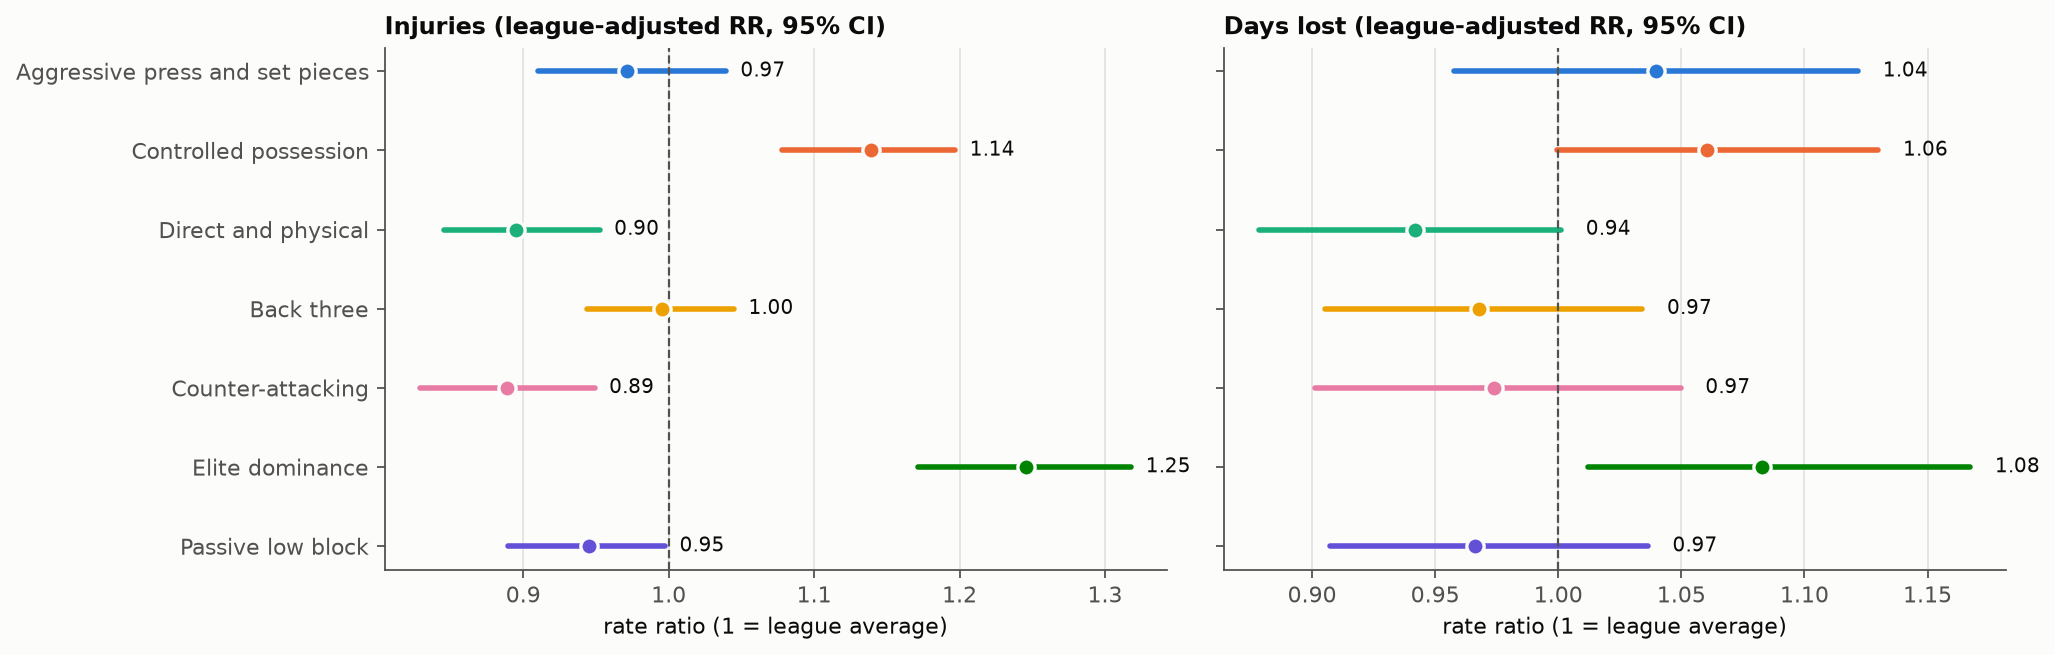

In [5]:
# Figure: league-adjusted rate ratios with 95% CIs, frequency and days lost, one row per style.
def ci_plot(ax, table: pd.DataFrame, rr: str, lo: str, hi: str, title: str) -> None:
    y = np.arange(len(table))[::-1]
    for yi, (name, r), color in zip(y, table.iterrows(), SERIES):
        ax.plot([r[lo], r[hi]], [yi, yi], color=color, linewidth=2.5, solid_capstyle="round")
        ax.scatter(r[rr], yi, s=60, color=color, edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(r[hi] + 0.01, yi, f"{r[rr]:.2f}", va="center", fontsize=9, color=INK)
    ax.axvline(1, color=MUTED, linewidth=1, linestyle="--")
    ax.set_yticks(y, table.index)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ci_plot(axes[0], by_style, "RR", "RR low", "RR high", "Injuries (league-adjusted RR, 95% CI)")
ci_plot(axes[1], by_style, "days RR", "days RR low", "days RR high", "Days lost (league-adjusted RR, 95% CI)")
for ax in axes:
    ax.set_xlabel("rate ratio (1 = league average)")
fig.tight_layout()
style_fig = save(fig, "05_rates_by_style.png")

## Step 4. Body areas by style

Share of each style's injuries per body area. *Unknown* is shown but left out of the test, since its share depends on
recording. Chi-square tests whether the body-area mix differs by style; Cramér's V says how much (0 = not at all,
0.1 small, 0.3 medium). Standardised residuals show which cells drive it (beyond ±2 = notably more or fewer injuries
there than if the mix were the same for every style).

In [6]:
AREA_COLS = [c for c in ps.columns if c.startswith("area: ")]
area_by_style = ps.groupby("cluster_name")[AREA_COLS].sum().loc[STYLE_ORDER].rename(columns=lambda c: c[6:])
area_order = area_by_style.sum().sort_values(ascending=False).index.tolist()
area_by_style = area_by_style[area_order]
known = area_by_style.drop(columns="unknown")
chi, p_area, dof_area, expected = chi2_contingency(known)
cramers_v = np.sqrt(chi / (known.to_numpy().sum() * (min(known.shape) - 1)))
residuals = (known - expected) / np.sqrt(expected)
area_share = area_by_style.div(area_by_style.sum(axis=1), axis=0)
print(f"chi² = {chi:.1f}, df = {dof_area}, p = {p_area:.2g}, Cramér's V = {cramers_v:.3f}")
display((100 * area_share).round(1))
residuals.round(1)

chi² = 244.0, df = 60, p = 4.9e-24, Cramér's V = 0.044


,unspecified muscle,knee,hamstring,unknown,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
cluster_name,,,,,,,,,,,,
Aggressive press and set pieces,20.6,16.3,11.8,11.5,9.6,8.2,7.0,3.2,4.6,4.0,2.0,1.3
Controlled possession,18.0,13.7,15.6,10.6,10.0,9.1,8.7,3.8,3.5,2.9,2.1,1.9
Direct and physical,18.3,15.6,12.6,16.6,8.7,7.3,6.6,4.5,3.7,3.4,1.8,1.0
Back three,19.2,13.8,12.7,15.1,8.8,7.9,8.0,3.7,3.8,3.0,2.3,1.7
Counter-attacking,17.7,14.9,11.6,12.1,9.0,9.4,6.5,5.4,5.0,3.6,2.8,2.0
Elite dominance,17.5,13.8,15.1,10.2,9.9,10.4,7.5,4.8,4.1,3.1,2.4,1.2
Passive low block,13.8,15.2,12.6,13.5,9.5,9.3,8.4,5.3,4.6,3.8,2.0,1.7


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
cluster_name,,,,,,,,,,,
Aggressive press and set pieces,3.5,2.0,-2.5,0.2,-1.4,-1.6,-3.5,1.1,1.7,-1.0,-1.4
Controlled possession,-0.2,-2.3,3.5,0.8,0.2,2.0,-2.0,-2.3,-1.9,-0.5,1.4
Direct and physical,1.9,2.2,-0.1,-0.6,-2.2,-1.6,0.9,-1.0,0.4,-1.1,-2.2
Back three,2.8,-0.9,-0.3,-0.7,-1.5,1.3,-1.6,-0.7,-1.1,0.9,0.8
Counter-attacking,-0.3,0.0,-2.4,-0.8,1.0,-2.3,2.5,2.0,0.5,2.1,1.9
Elite dominance,-0.9,-1.9,2.2,0.4,2.5,-0.8,0.7,-0.6,-1.1,0.7,-1.7
Passive low block,-6.1,1.0,-0.9,0.5,1.4,2.0,3.3,1.7,1.7,-0.7,1.0


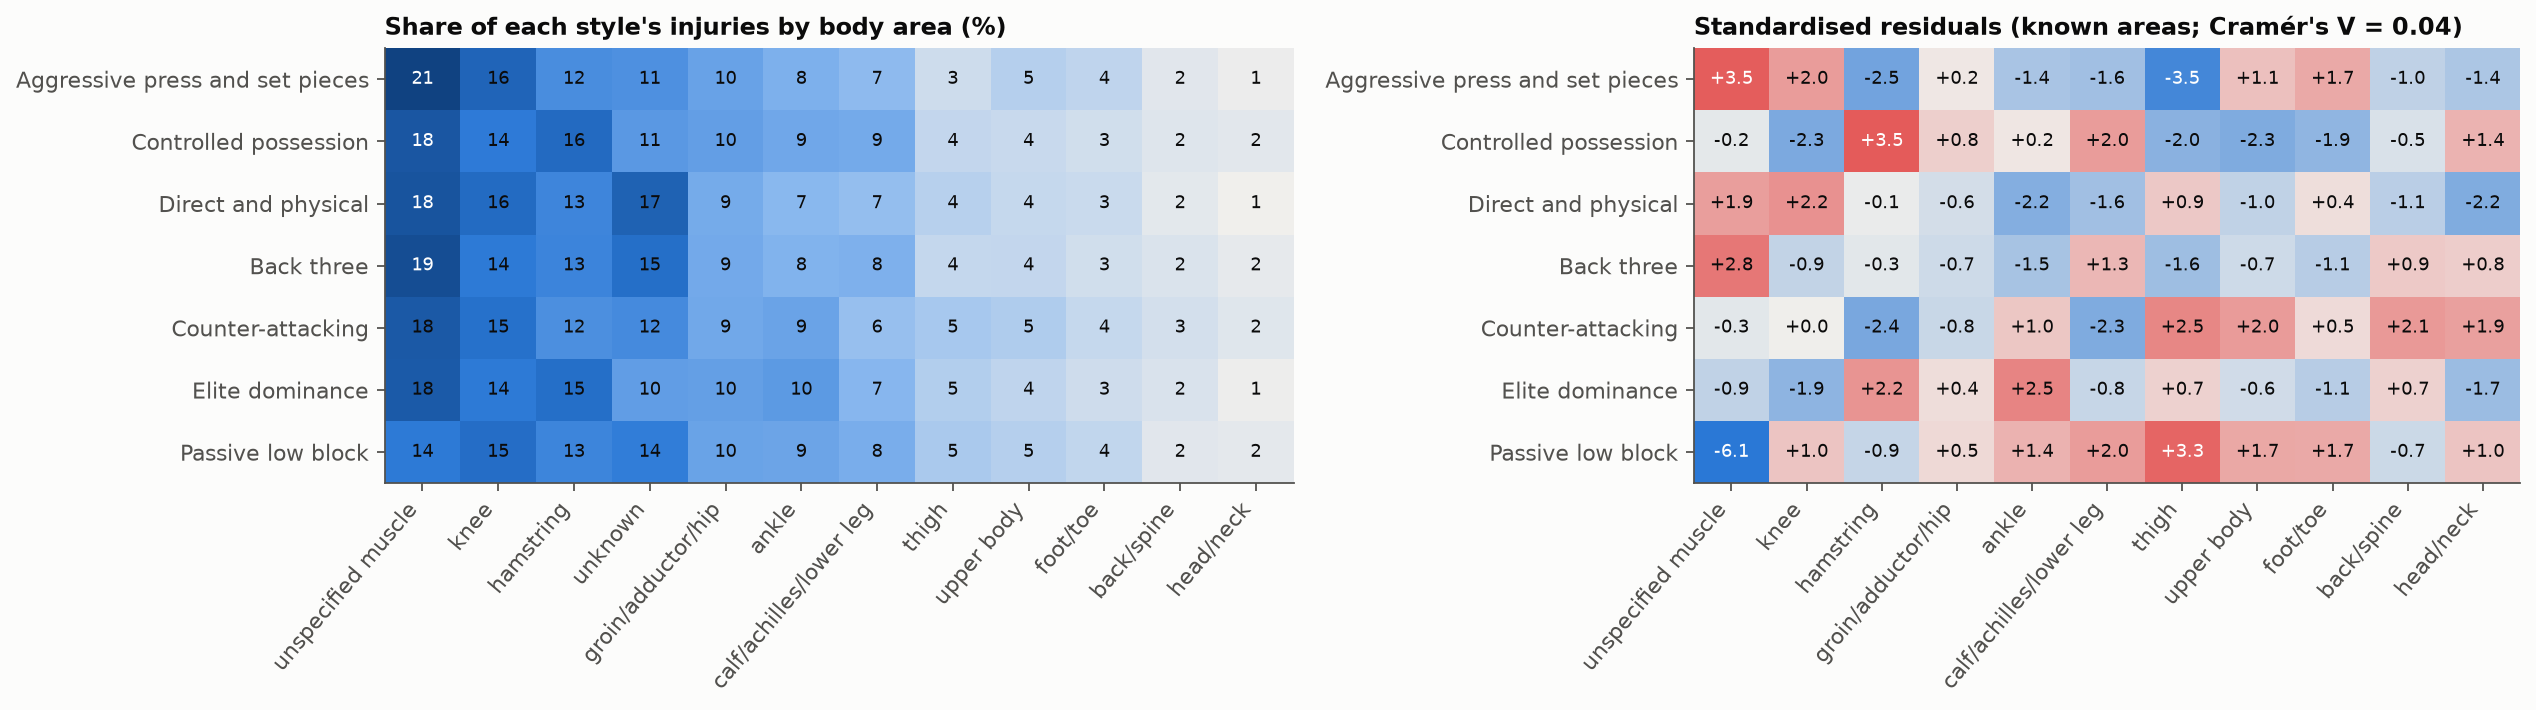

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
im = axes[0].imshow(100 * area_share.to_numpy(), cmap=SEQUENTIAL, aspect="auto")
axes[0].set_title("Share of each style's injuries by body area (%)", loc="left")
axes[1].imshow(residuals.to_numpy(), cmap=DIVERGING, vmin=-4, vmax=4, aspect="auto")
axes[1].set_title(f"Standardised residuals (known areas; Cramér's V = {cramers_v:.2f})", loc="left")
for ax, data, fmtv in [(axes[0], 100 * area_share, "{:.0f}"), (axes[1], residuals, "{:+.1f}")]:
    ax.set_xticks(range(data.shape[1]), data.columns, rotation=50, ha="right")
    ax.set_yticks(range(data.shape[0]), data.index)
    ax.grid(False)
    vals = data.to_numpy()
    for (i, j), v in np.ndenumerate(vals):
        dark = (v > 18) if ax is axes[0] else abs(v) > 3
        ax.text(j, i, fmtv.format(v), ha="center", va="center", fontsize=8, color="white" if dark else INK)
fig.tight_layout()
area_fig = save(fig, "05_body_areas_by_style.png")

### Within each league

Leagues label injuries differently (e.g. *unspecified muscle* is 29% of La Liga injuries but 7% of Premier League
ones), so a style common in one league could look different only because of labelling. For each body area: the
style's share **within a league** relative to that league's share (1 = same), and in how many of the 5 leagues it is
above 1. A difference that holds in 4–5 leagues is a style pattern; one that flips between leagues is labelling.

In [8]:
AREAS_CHECK = [a for a in area_order if a != "unknown"][:7]
within_area = {}
for a in AREAS_CHECK:
    g = ps.groupby(["league", "cluster_name"])[[f"area: {a}", "injuries"]].sum()
    lg = ps.groupby("league")[[f"area: {a}", "injuries"]].sum()
    within_area[a] = (g[f"area: {a}"] / g.injuries).unstack().div(lg[f"area: {a}"] / lg.injuries, axis=0)[STYLE_ORDER]
leagues_above = pd.DataFrame({a: (t > 1).sum() for a, t in within_area.items()}).loc[STYLE_ORDER]
median_rel = pd.DataFrame({a: t.median() for a, t in within_area.items()}).loc[STYLE_ORDER].round(2)
display(within_area["hamstring"].round(2))
display(leagues_above.rename(columns=lambda c: f"{c}: leagues > 1"))
median_rel

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Bundesliga,0.70,0.97,0.73,1.55,1.19,1.02,0.82
La Liga,0.92,1.05,0.97,0.42,1.15,1.15,1.09
Ligue 1,1.40,1.09,0.97,0.79,0.69,1.11,0.84
Premier League,0.82,1.04,1.23,0.94,0.98,1.01,0.97
Serie A,0.95,1.19,0.91,1.08,0.86,1.22,0.76


,unspecified muscle: leagues > 1,knee: leagues > 1,hamstring: leagues > 1,groin/adductor/hip: leagues > 1,ankle: leagues > 1,calf/achilles/lower leg: leagues > 1,thigh: leagues > 1
cluster_name,,,,,,,
Aggressive press and set pieces,0,2,1,2,0,2,1
Controlled possession,4,2,4,2,4,4,1
Direct and physical,1,5,1,3,2,0,3
Back three,3,2,2,1,2,4,0
Counter-attacking,1,3,2,4,3,1,4
Elite dominance,4,1,5,3,4,2,2
Passive low block,2,3,1,1,2,2,4


,unspecified muscle,knee,hamstring,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh
cluster_name,,,,,,,
Aggressive press and set pieces,0.92,0.99,0.92,0.96,0.95,0.96,0.94
Controlled possession,1.08,0.98,1.05,0.99,1.02,1.09,0.75
Direct and physical,0.93,1.16,0.97,1.05,0.95,0.88,1.03
Back three,1.03,0.94,0.94,0.91,0.90,1.11,0.87
Counter-attacking,0.89,1.09,0.98,1.03,1.13,0.93,1.21
Elite dominance,1.19,0.88,1.11,1.11,1.04,1.00,0.74
Passive low block,0.89,1.00,0.84,0.96,0.97,0.99,1.26


## Step 5. Seasons

Injuries per player-season by season (raw, with 95% CIs), with the calendar events from the project notes, and how
the share of each style changed per league. Raw season rates mix real change with Transfermarkt's recording changes
(Phase 0: Premier League 2018-19 jump), so the per-league view and the share of unknown body areas are shown with it.

In [9]:
by_season = summarise(ps, "season_key")
unknown_share = (ps.groupby("season_key")["area: unknown"].sum() / ps.groupby("season_key").injuries.sum()).rename("unknown body area")
season_league = ps.groupby(["season_key", "league"]).apply(lambda d: d.injuries.sum() / len(d), include_groups=False).unstack()[LEAGUES]
style_share = pd.crosstab([clusters.league, clusters.season_key], clusters.cluster_name, normalize="index")[STYLE_ORDER]
display(fmt(by_season).join(unknown_share.round(3)))
display(season_league.round(3))

,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI),unknown body area
season_key,,,,,,,,,,
2014-15,2939,98,1741,0.592,0.398,29.1,0.480,0.88 (0.81–0.96),0.95 (0.86–1.07),0.157
2015-16,3008,98,1835,0.610,0.417,29.6,0.458,0.91 (0.82–0.99),0.97 (0.88–1.06),0.137
2016-17,3005,98,2124,0.707,0.487,33.4,0.470,1.05 (0.98–1.13),1.10 (1.01–1.19),0.123
2017-18,2997,98,2015,0.672,0.460,29.6,0.427,1.00 (0.93–1.07),0.97 (0.89–1.05),0.099
2018-19,2944,98,2298,0.781,0.526,33.0,0.423,1.16 (1.07–1.26),1.08 (1.00–1.16),0.138
2019-20,3032,98,2166,0.714,0.521,31.9,0.429,1.06 (0.98–1.15),1.05 (0.96–1.14),0.096
2020-21,3161,98,2072,0.655,0.481,26.3,0.396,0.97 (0.90–1.06),0.86 (0.78–0.95),0.156
2021-22,3233,98,1919,0.594,0.442,25.7,0.445,0.88 (0.81–0.96),0.85 (0.77–0.92),0.145
2022-23,3148,98,1934,0.614,0.445,28.1,0.471,0.92 (0.84–0.99),0.92 (0.85–1.00),0.142


league,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
season_key,,,,,
2014-15,0.600,0.516,0.693,0.849,0.320
2015-16,0.505,0.654,0.776,0.783,0.356
2016-17,0.565,0.891,0.740,0.900,0.465
2017-18,0.567,0.773,0.753,0.926,0.354
2018-19,1.077,0.798,0.773,0.894,0.374
2019-20,0.899,0.677,0.816,0.765,0.392
2020-21,0.677,0.490,0.871,0.746,0.483
2021-22,0.501,0.473,0.862,0.663,0.456
2022-23,0.552,0.409,0.870,0.673,0.568


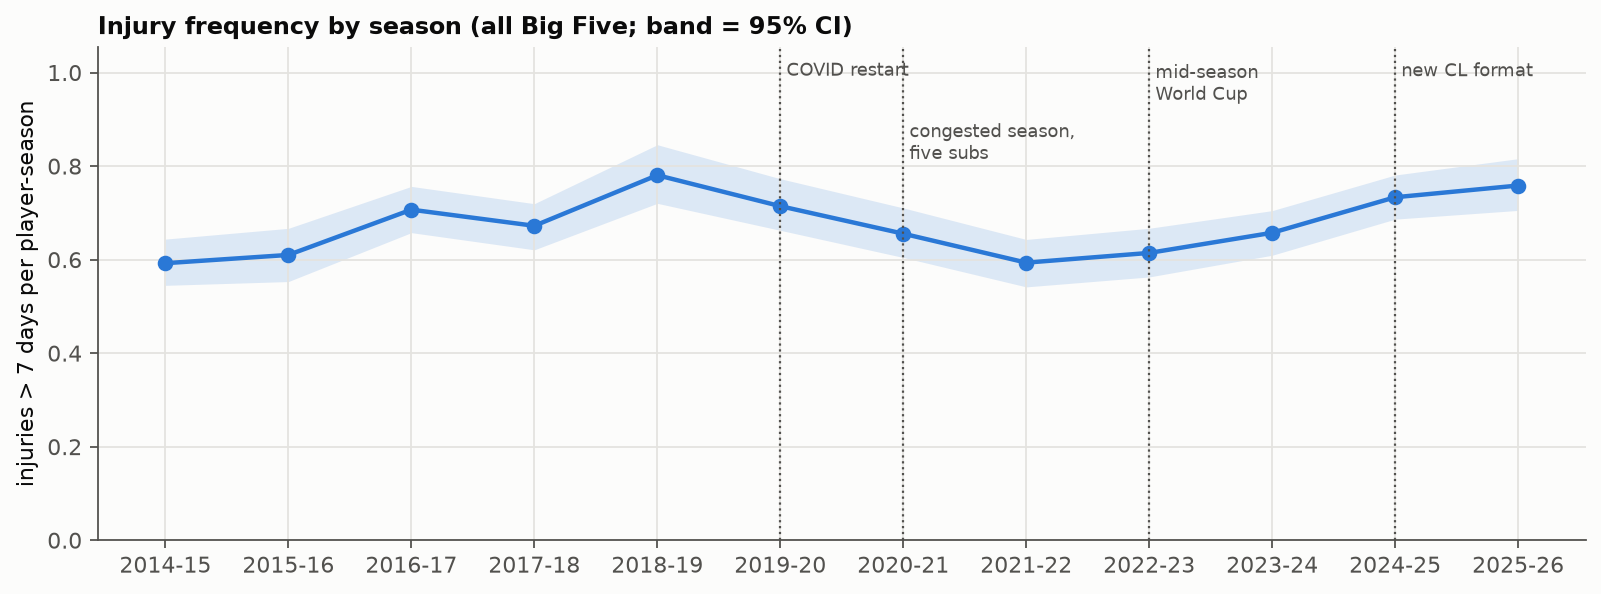

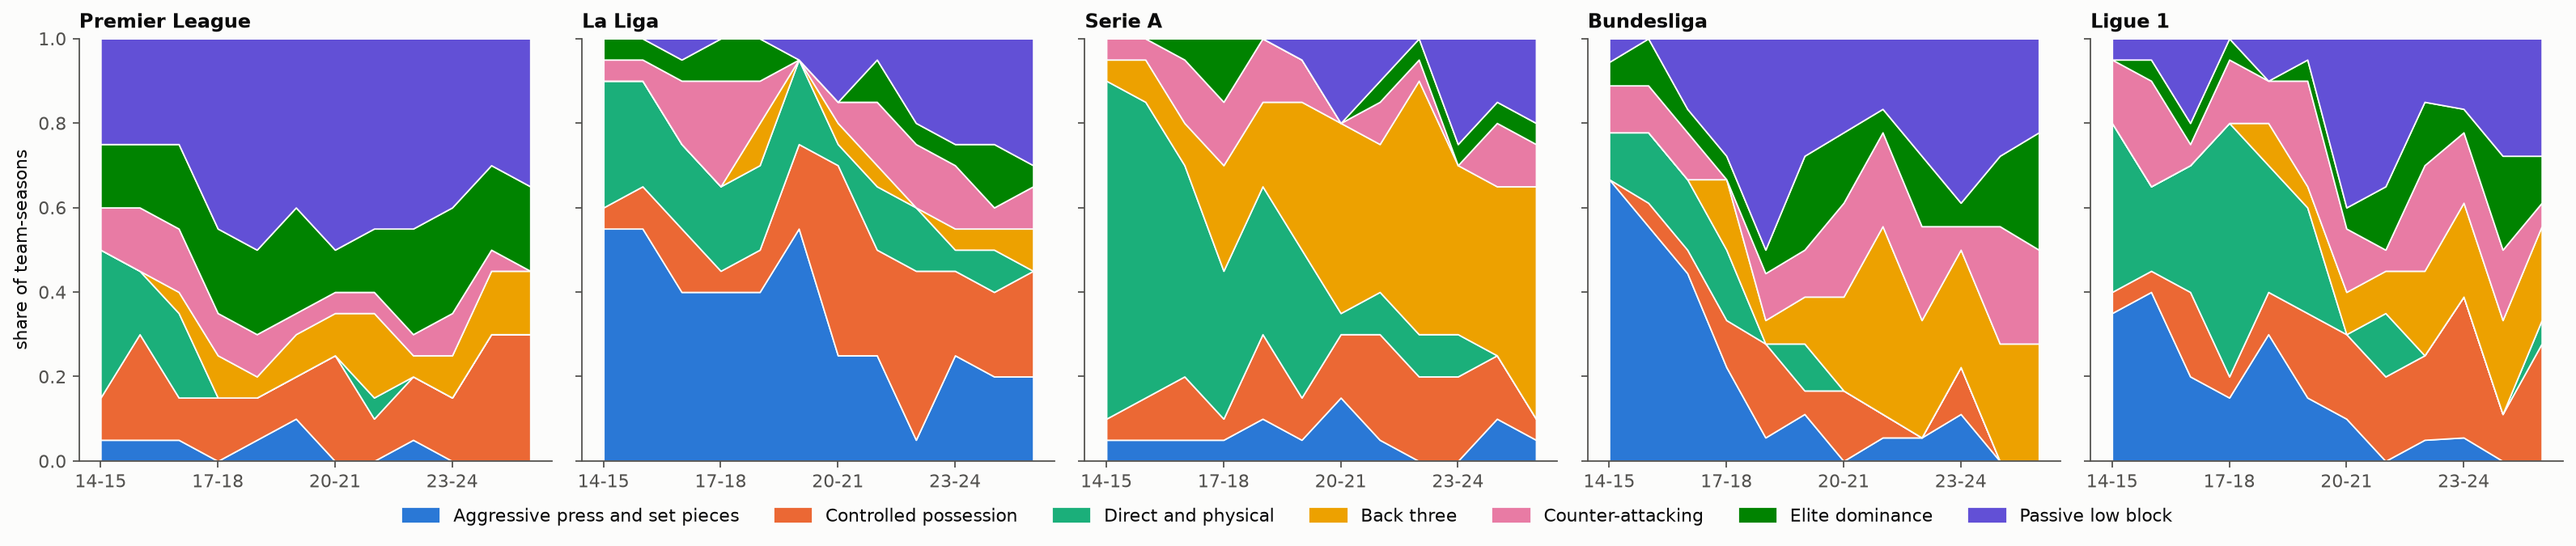

In [10]:
EVENTS = {"2019-20": "COVID restart", "2020-21": "congested season,\nfive subs", "2022-23": "mid-season\nWorld Cup",
          "2024-25": "new CL format"}
LABEL_Y = {"2019-20": 0.97, "2020-21": 0.85, "2022-23": 0.97, "2024-25": 0.97}  # stagger neighbouring labels
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(by_season))
ax.fill_between(x, by_season["injuries / player-season"] * by_season["RR low"] / by_season["RR"],
                by_season["injuries / player-season"] * by_season["RR high"] / by_season["RR"], color=SERIES[0], alpha=0.15, linewidth=0)
ax.plot(x, by_season["injuries / player-season"], color=SERIES[0], marker="o", markersize=6)
ax.set_xticks(x, by_season.index)
ax.set_ylabel("injuries > 7 days per player-season")
ax.set_ylim(0, by_season["injuries / player-season"].max() * 1.35)
for s, label in EVENTS.items():
    xi = list(by_season.index).index(s)
    ax.axvline(xi, color=MUTED, linewidth=1, linestyle=":")
    ax.text(xi + 0.05, ax.get_ylim()[1] * LABEL_Y[s], label, fontsize=8, color=MUTED, va="top")
ax.set_title("Injury frequency by season (all Big Five; band = 95% CI)", loc="left")
trend_fig = save(fig, "05_season_trend.png")

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, lg in zip(axes, LEAGUES):
    d = style_share.loc[lg].reindex(by_season.index).fillna(0)
    ax.stackplot(range(len(d)), d.T.to_numpy(), colors=SERIES[:len(STYLE_ORDER)], edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(lg, loc="left")
    ax.set_xticks(range(0, len(d), 3), [d.index[i][2:] for i in range(0, len(d), 3)])
    ax.set_ylim(0, 1)
    ax.grid(False)
axes[0].set_ylabel("share of team-seasons")
handles = [plt.Rectangle((0, 0), 1, 1, color=SERIES[i]) for i in range(len(STYLE_ORDER))]
fig.legend(handles, STYLE_ORDER, loc="lower center", ncol=len(STYLE_ORDER), frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout()
shares_fig = save(fig, "05_style_shares_by_league.png")

## Step 6. Leagues

Rates and body-area mix per league (raw: these differ partly because of recording), and the **style effect within
each league**: the RR of each style against its own league's average (the league-adjusted RR computed separately per
league). A pattern that holds in several leagues is more convincing than one carried by a single league.

In [11]:
by_league = summarise(ps, "league").loc[LEAGUES]
league_area = ps.groupby("league")[AREA_COLS].sum().loc[LEAGUES].rename(columns=lambda c: c[6:])[area_order]
league_area_share = league_area.div(league_area.sum(axis=1), axis=0)
within = summarise(ps, ["league", "cluster_name"])
rr_within = within["RR"].unstack()[STYLE_ORDER].loc[LEAGUES]
n_within = within["team-seasons"].unstack()[STYLE_ORDER].loc[LEAGUES]
display(fmt(by_league))
display((100 * league_area_share).round(1))
display(rr_within.round(2))
n_within

,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
league,,,,,,,,,
Premier League,7524,240,5151,0.685,0.451,36.2,0.512,1.00 (0.95–1.06),1.00 (0.94–1.06)
La Liga,7429,240,4451,0.599,0.402,26.9,0.448,1.00 (0.93–1.07),1.00 (0.93–1.06)
Serie A,7787,240,6410,0.823,0.608,30.4,0.371,1.00 (0.96–1.04),1.00 (0.95–1.05)
Bundesliga,6616,216,5227,0.790,0.593,37.7,0.474,1.00 (0.96–1.04),1.00 (0.95–1.05)
Ligue 1,7169,234,3342,0.466,0.334,21.5,0.452,1.00 (0.94–1.06),1.00 (0.93–1.07)


,unspecified muscle,knee,hamstring,unknown,groin/adductor/hip,ankle,calf/achilles/lower leg,thigh,upper body,foot/toe,back/spine,head/neck
league,,,,,,,,,,,,
Premier League,6.6,16.4,19.0,13.7,9.8,10.5,8.6,3.4,3.9,3.9,2.3,1.8
La Liga,29.0,13.9,15.7,6.7,8.2,7.8,7.5,1.6,3.7,3.3,1.5,0.9
Serie A,20.3,12.3,13.0,20.4,7.9,6.6,7.7,3.4,3.5,2.2,1.8,1.1
Bundesliga,22.5,16.5,6.0,10.5,9.7,9.9,6.0,3.3,5.6,4.4,3.2,2.3
Ligue 1,7.4,15.4,12.6,9.2,12.7,9.8,8.8,13.0,4.1,3.6,2.0,1.6


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Premier League,1.04,1.09,0.80,0.87,0.77,1.24,0.94
La Liga,0.93,1.24,0.97,1.04,0.83,1.49,0.65
Serie A,0.99,1.07,0.90,1.06,0.92,0.90,1.14
Bundesliga,1.00,1.04,1.20,0.89,1.01,1.09,0.97
Ligue 1,1.01,1.22,0.70,1.03,0.83,1.64,0.97


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
league,,,,,,,
Premier League,7,41,15,21,19,46,91
La Liga,81,48,37,8,25,15,26
Serie A,14,33,68,76,21,9,19
Bundesliga,41,15,13,38,32,26,51
Ligue 1,35,38,45,23,35,18,40


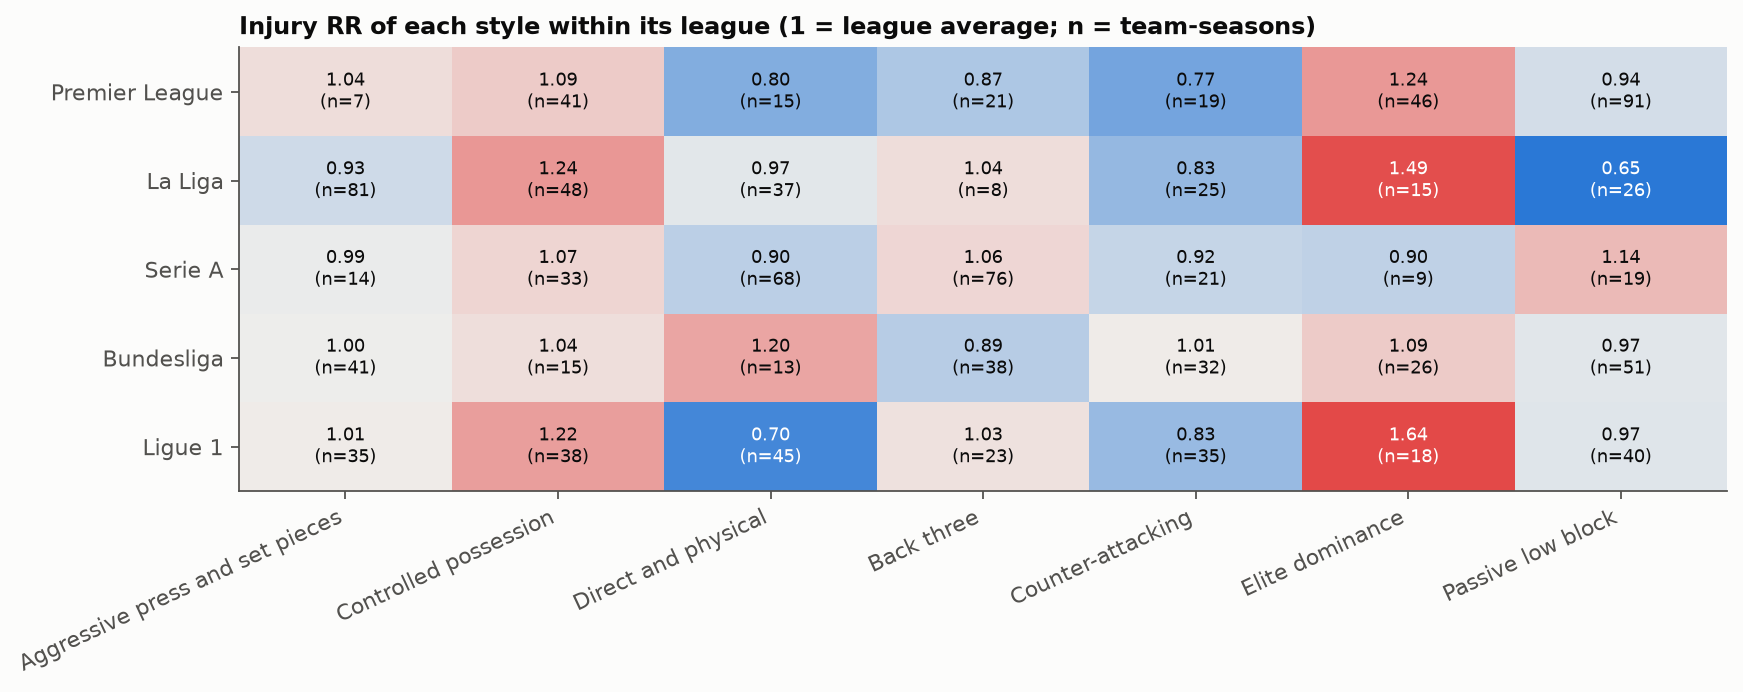

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.6))
vals = rr_within.to_numpy()
ax.imshow(np.log2(vals), cmap=DIVERGING, vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(STYLE_ORDER)), STYLE_ORDER, rotation=25, ha="right")
ax.set_yticks(range(len(LEAGUES)), LEAGUES)
ax.grid(False)
for (i, j), v in np.ndenumerate(vals):
    n = n_within.to_numpy()[i, j]
    ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}\n(n={int(n)})", ha="center", va="center", fontsize=8,
            color=INK if np.isnan(v) or abs(np.log2(v)) < 0.45 else "white")
ax.set_title("Injury RR of each style within its league (1 = league average; n = team-seasons)", loc="left")
league_fig = save(fig, "05_style_within_league.png")

## Step 7. Age and position

Styles differ in squad make-up (e.g. elite clubs field older players). If the style differences in step 3 were only
the age and position mix, they would shrink when the expected injuries come from **league × age band × position**
instead of league alone. Rates by age band and position are shown for context.

In [13]:
compare = pd.DataFrame({
    "RR, league-adjusted": by_style["RR"], "RR, league × age × position": by_style_lap["RR"],
    "days RR, league-adjusted": by_style["days RR"], "days RR, league × age × position": by_style_lap["days RR"],
}).round(2)
mix = pd.concat([ps.groupby("cluster_name").age.mean().round(1).rename("mean age"),
                 pd.crosstab(ps.cluster_name, ps.position, normalize="index").round(2)], axis=1).loc[STYLE_ORDER]
display(compare.join(mix))
display(fmt(summarise(ps.dropna(subset=["age_band"]), "age_band"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]])
fmt(summarise(ps.dropna(subset=["position"]), "position"))[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]]

,"RR, league-adjusted","RR, league × age × position","days RR, league-adjusted","days RR, league × age × position",mean age,Defender,Forward,Goalkeeper,Midfielder
cluster_name,,,,,,,,,
Aggressive press and set pieces,0.97,0.97,1.04,1.04,25.9,0.33,0.29,0.09,0.29
Controlled possession,1.14,1.16,1.06,1.07,25.7,0.34,0.28,0.08,0.30
Direct and physical,0.90,0.89,0.94,0.94,26.0,0.34,0.28,0.08,0.31
Back three,1.00,0.99,0.97,0.97,25.9,0.35,0.26,0.09,0.31
Counter-attacking,0.89,0.89,0.97,0.97,25.9,0.33,0.29,0.09,0.29
Elite dominance,1.25,1.29,1.08,1.11,25.4,0.34,0.25,0.09,0.31
Passive low block,0.95,0.93,0.97,0.95,26.2,0.34,0.29,0.09,0.29


,player-seasons,injuries / player-season,days lost / player-season,severe share
age_band,,,,
≤21,6166,0.365,19.6,0.519
22–25,10553,0.628,29.4,0.466
26–29,10525,0.774,34.4,0.432
30+,9260,0.814,34.5,0.426


,player-seasons,injuries / player-season,days lost / player-season,severe share
position,,,,
Defender,12362,0.755,34.5,0.448
Forward,10152,0.661,29.7,0.438
Goalkeeper,3127,0.418,21.3,0.511
Midfielder,10884,0.664,29.3,0.443


## Step 8. Team strength and workload

Styles partly follow team strength (Phase 4: eta² = 0.41 for points). **Strength:** the style RRs within each third
of teams by points per match: if a style's pattern holds among similarly strong teams, it is not just strength.
**Workload:** players of teams in the busiest third (share of matches on < 4 days' rest) vs the rest, within each
style: is congestion linked to injuries regardless of style?

In [14]:
rr_strength = summarise(ps, ["strength", "cluster_name"])["RR"].unstack()[STYLE_ORDER]
n_strength = summarise(ps, ["strength", "cluster_name"])["team-seasons"].unstack()[STYLE_ORDER]
ps["congestion"] = pd.qcut(ps.short_rest_share, 3, labels=["lightest third", "middle third", "busiest third"], duplicates="drop")
by_congestion = summarise(ps, "congestion")
rr_congestion = summarise(ps, ["congestion", "cluster_name"])["RR"].unstack()[STYLE_ORDER]
display(rr_strength.round(2))
display(n_strength)
display(fmt(by_congestion))
rr_congestion.round(2)

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
strength,,,,,,,
middle third,1.05,1.01,0.87,0.93,0.92,1.05,0.97
stronger third,1.12,1.18,0.98,1.08,0.97,1.27,1.04
weaker third,0.82,1.18,0.89,0.98,0.86,0.78,0.92


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
strength,,,,,,,
middle third,68,43,64,60,46,4,86
stronger third,39,123,27,59,15,107,19
weaker third,71,9,87,47,71,3,122


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
congestion,,,,,,,,,
lightest third,12400,397,8048,0.649,0.521,29.7,0.455,0.94 (0.91–0.97),0.98 (0.94–1.03)
middle third,11970,386,7200,0.602,0.437,28.5,0.459,0.92 (0.88–0.96),0.95 (0.90–1.00)
busiest third,12155,387,9333,0.768,0.469,33.2,0.431,1.14 (1.10–1.18),1.07 (1.02–1.11)


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
congestion,,,,,,,
busiest third,1.21,1.16,0.99,1.05,1.02,1.26,1.04
lightest third,0.86,1.12,0.87,0.99,0.88,1.05,0.99
middle third,0.86,1.09,0.88,0.93,0.85,1.24,0.85


## Step 9. Fitness absences (secondary outcome)

*Fitness* absences are not injuries (Phase 2) but may show loss of conditioning. They are recorded almost only in
the Bundesliga (10.9 per 100 player-seasons vs ≤ 1.1 elsewhere), so they are compared by style **within the
Bundesliga**.

In [15]:
bl = ps[ps.league == "Bundesliga"]
fitness = bl.groupby("cluster_name").agg(player_seasons=("playerId", "size"), fitness_absences=("fitness_absences", "sum"))
fitness["per 100 player-seasons"] = (100 * fitness.fitness_absences / fitness.player_seasons).round(1)
fitness.loc[STYLE_ORDER]

,player_seasons,fitness_absences,per 100 player-seasons
cluster_name,,,
Aggressive press and set pieces,1237,142,11.5
Controlled possession,455,31,6.8
Direct and physical,403,61,15.1
Back three,1189,144,12.1
Counter-attacking,980,98,10.0
Elite dominance,804,99,12.3
Passive low block,1548,145,9.4


## Step 10. Sensitivity checks

The league-adjusted RR by style under each variation in the plan. A finding is robust if its direction holds in
every row. (Expected injuries are recomputed within each variant.)

In [16]:
def rr_variant(df: pd.DataFrame, count: str = "injuries") -> pd.Series:
    d = df.assign(injuries=df[count])
    d = add_expected(d, ["league"])
    t = summarise(d, "cluster_name")
    return t["RR"].reindex(STYLE_ORDER)


variants = {
    "main (> 7 days)": rr_variant(ps),
    "≥ 900 minutes only": rr_variant(ps[ps.minutes >= 900]),
    "severe only (> 28 days)": rr_variant(ps, "severe"),
    "> 3 days (adds mild)": rr_variant(ps.assign(more=ps.injuries + ps.mild_injuries), "more"),
    "multi-club players out": rr_variant(ps[ps.clubs_in_season == 1]),
    "COVID seasons out": rr_variant(ps[~ps.season_key.isin(COVID_SEASONS)]),
}
sensitivity = pd.DataFrame(variants).T.round(2)
direction = (np.sign(sensitivity - 1).nunique() == 1)
k4 = summarise(ps, "cluster_k4_name")
display(sensitivity)
print("same direction in every variant:", direction[direction].index.tolist())
fmt(k4)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share", "RR (95% CI)", "days RR (95% CI)"]]

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
main (> 7 days),0.97,1.14,0.90,1.00,0.89,1.25,0.95
≥ 900 minutes only,0.95,1.15,0.87,1.01,0.87,1.33,0.90
severe only (> 28 days),0.99,1.10,0.98,0.93,0.97,1.09,0.97
> 3 days (adds mild),0.97,1.16,0.86,1.01,0.87,1.31,0.93
multi-club players out,0.97,1.15,0.89,1.00,0.89,1.26,0.93
COVID seasons out,0.97,1.17,0.89,1.01,0.89,1.27,0.92


same direction in every variant: ['Aggressive press and set pieces', 'Controlled possession', 'Direct and physical', 'Counter-attacking', 'Elite dominance', 'Passive low block']


,player-seasons,injuries / player-season,days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
cluster_k4_name,,,,,,
Back three,6478,0.735,31.0,0.405,0.99 (0.95–1.03),0.97 (0.92–1.03)
Direct and physical,10674,0.604,28.0,0.459,0.93 (0.89–0.97),0.99 (0.94–1.04)
Dominant pressing,8015,0.798,34.0,0.426,1.21 (1.15–1.26),1.09 (1.03–1.14)
Passive low block,11358,0.614,30.0,0.485,0.93 (0.88–0.97),0.96 (0.91–1.01)


## Step 12. Style cards: what each style looks like on the pitch

Many team-seasons sit between two styles, so each style is described from its **core** team-seasons: those clearly
closer to their own style than to any other (distance to own centroid ≤ 80% of the distance to the next one).
Each card gives the three traits that set the style apart (largest centroid scores), the matching numbers in real
units against the all-team average, typical core teams in each era, and the family it belongs to at k = 4.

In [17]:
CORE_RATIO = 0.8
ERAS = {range(2014, 2018): "2014–18", range(2018, 2022): "2018–22", range(2022, 2026): "2022–26"}
ERA_ORDER = list(ERAS.values())


def era_of(season: int) -> str:
    return next(label for years, label in ERAS.items() if season in years)


DIMS = ["dominance", "pressing", "counter", "high_line", "physical", "set_pieces", "long_shots", "back_three"]
RAW = {"dominance": ("deep_pm", "deep completions per match"), "pressing": ("ppda", "PPDA (lower = more pressing)"),
       "counter": ("fast_attack_share", "shots from fast attacks"), "high_line": ("conceded_fast_share", "shots conceded from fast attacks"),
       "physical": ("fouls_pm", "fouls per match"), "set_pieces": ("set_piece_share", "shots from set pieces"),
       "long_shots": ("outside_box_share", "shots from outside the box"), "back_three": ("back_three_share", "minutes in a back three")}
PHRASE = {"dominance": ("dominates the ball and plays in the opponent's half", "spends long spells without the ball"),
          "pressing": ("presses high and wins the ball back fast", "sits off and lets the opponent play"),
          "counter": ("strikes on the break", "rarely attacks fast"),
          "high_line": ("holds a high line, exposed to counters", "defends deep, rarely caught on the break"),
          "physical": ("physical: many fouls, cards and duels", "clean: few fouls and cards"),
          "set_pieces": ("relies on set pieces", "creates little from set pieces"),
          "long_shots": ("shoots from distance", "works the ball into the box"),
          "back_three": ("plays with a back three", "plays with a back four")}

style_dims = pd.read_parquet(DATA_DIR / "03_features" / "style_dimensions.parquet").rename(columns={"tm_club_id": "club_id"})
ts = (clusters.merge(style_dims[["season", "club_id"] + DIMS], on=["season", "club_id"])
      .merge(team[["season", "club_id", "points_pm", "matches_europe"]], on=["season", "club_id"])
      .merge(features[["season", "club_id"] + [r for r, _ in RAW.values()]], on=["season", "club_id"]))
ts["era"] = ts.season.map(era_of)
centroids = ts.groupby("cluster")[DIMS].mean()
dist = np.linalg.norm(ts[DIMS].to_numpy()[:, None, :] - centroids.to_numpy()[None, :, :], axis=2)
own = dist[np.arange(len(ts)), ts.cluster.to_numpy() - 1]
dist[np.arange(len(ts)), ts.cluster.to_numpy() - 1] = np.inf
ts["typicality"] = own / dist.min(axis=1)
ts["core"] = ts.typicality <= CORE_RATIO
ts["dist_own"] = own


def value(feature: str, v: float) -> str:
    return f"{100 * v:.0f}%" if feature.endswith("share") else f"{v:.1f}"


cards = []
for name in STYLE_ORDER:
    s = ts[ts.cluster_name == name]
    core = s[s.core]
    cz = core[DIMS].mean()
    top = cz.abs().sort_values(ascending=False).index[:3]
    traits = [PHRASE[d][0 if cz[d] > 0 else 1] for d in top]
    numbers = [f"{RAW[d][1]}: {value(RAW[d][0], core[RAW[d][0]].mean())} (all teams {value(RAW[d][0], ts[RAW[d][0]].mean())})" for d in top]
    typical = (core.sort_values("dist_own").groupby("era").head(2).assign(t=lambda d: d.club + " " + d.season_key)
               .groupby("era").t.apply(", ".join).reindex(ERA_ORDER).fillna("–"))
    cards.append({"style": name, "family (k = 4)": s.cluster_k4_name.mode()[0], "team-seasons": len(s),
                  "core": f"{len(core)} ({len(core) / len(s):.0%})", "how it plays": "; ".join(traits),
                  "in numbers (core)": "; ".join(numbers), "points/match": round(core.points_pm.mean(), 2),
                  "European matches": round(core.matches_europe.mean(), 1),
                  **{f"typical {e}": typical[e] for e in ERA_ORDER}})
cards = pd.DataFrame(cards).set_index("style")
ps = ps.merge(ts[["season", "club_id", "core", "era"]], on=["season", "club_id"], how="left")
cards

,family (k = 4),team-seasons,core,how it plays,in numbers (core),points/match,European matches,typical 2014–18,typical 2018–22,typical 2022–26
style,,,,,,,,,,
Aggressive press and set pieces,Direct and physical,178,86 (48%),"physical: many fouls, cards and duels; relies ...",fouls per match: 14.7 (all teams 12.5); shots ...,1.27,3.0,"AS Monaco 2017-18, FC Toulouse 2016-17","Cagliari Calcio 2018-19, CA Osasuna 2019-20","Real Sociedad 2025-26, Cádiz CF 2023-24"
Controlled possession,Dominant pressing,175,86 (49%),dominates the ball and plays in the opponent's...,deep completions per match: 7.6 (all teams 6.1...,1.79,7.3,"Southampton FC 2014-15, Real Madrid 2015-16","LOSC Lille 2021-22, Athletic Bilbao 2020-21","Chelsea FC 2025-26, Stade Reims 2023-24"
Direct and physical,Direct and physical,178,86 (48%),"shoots from distance; physical: many fouls, ca...",shots from outside the box: 46% (all teams 38%...,1.14,0.9,"GFC Ajaccio 2015-16, SM Caen 2017-18","Rayo Vallecano 2018-19, FC Girondins Bordeaux ...","US Lecce 2022-23, Real Valladolid CF 2022-23"
Back three,Back three,166,112 (67%),plays with a back three; works the ball into t...,minutes in a back three: 87% (all teams 23%); ...,1.44,4.0,"Genoa CFC 2017-18, Eintracht Frankfurt 2017-18","TSG 1899 Hoffenheim 2020-21, Udinese Calcio 20...","1.FSV Mainz 05 2022-23, FC Toulouse 2025-26"
Counter-attacking,Passive low block,132,62 (47%),strikes on the break; spends long spells witho...,shots from fast attacks: 9% (all teams 6%); de...,1.16,1.1,"Angers SCO 2017-18, Stade Rennais FC 2014-15","Hertha BSC 2019-20, Hertha BSC 2020-21","UD Almería 2023-24, Angers SCO 2022-23"
Elite dominance,Dominant pressing,114,77 (68%),dominates the ball and plays in the opponent's...,deep completions per match: 11.1 (all teams 6....,2.12,10.3,"Inter Milan 2017-18, Paris Saint-Germain 2015-16","Paris Saint-Germain 2021-22, Borussia Dortmund...","Brighton & Hove Albion 2022-23, FC Barcelona 2..."
Passive low block,Passive low block,227,109 (48%),sits off and lets the opponent play; relies on...,PPDA (lower = more pressing): 13.5 (all teams ...,1.06,1.0,"Crystal Palace 2017-18, West Bromwich Albion 2...","Aston Villa 2021-22, Dijon FCO 2020-21","FC Nantes 2022-23, VfL Wolfsburg 2024-25"


## Step 13. Core teams only

If a style's injury pattern comes from the style itself, it should be at least as clear among its **core** teams
(clear examples of the style) as among all its teams, borderline ones included.

In [18]:
core_check = pd.DataFrame({
    "RR, all teams": by_style["RR"], "RR, core teams": summarise(ps[ps.core], "cluster_name").loc[STYLE_ORDER, "RR"],
    "days RR, all teams": by_style["days RR"], "days RR, core teams": summarise(ps[ps.core], "cluster_name").loc[STYLE_ORDER, "days RR"],
}).round(2)
core_check["share of player-seasons in core teams"] = ps.groupby("cluster_name").core.mean().loc[STYLE_ORDER].round(2)
core_check

,"RR, all teams","RR, core teams","days RR, all teams","days RR, core teams",share of player-seasons in core teams
cluster_name,,,,,
Aggressive press and set pieces,0.97,0.95,1.04,1.11,0.49
Controlled possession,1.14,1.19,1.06,1.02,0.49
Direct and physical,0.90,0.84,0.94,0.90,0.49
Back three,1.00,1.00,0.97,0.97,0.68
Counter-attacking,0.89,0.93,0.97,0.98,0.46
Elite dominance,1.25,1.25,1.08,1.07,0.67
Passive low block,0.95,0.93,0.97,0.93,0.48


## Step 14. How the ways of playing changed, and in what shape

Each style dimension averaged per era (2014–18, 2018–22, 2022–26) for all leagues and for each league, with the shape
of the change: **rising**, **falling**, **peak** (up then down), **dip** (down then up) or **flat** (every step smaller
than 0.1 standard deviations). Raw-unit season means show the same changes in football terms.

In [19]:
SHAPE_TOL = 0.1


def shape(values: list[float]) -> str:
    steps = [0 if abs(d) < SHAPE_TOL else int(np.sign(d)) for d in np.diff(values)]
    if steps == [0, 0]:
        return "flat"
    if all(x >= 0 for x in steps):
        return "rising"
    if all(x <= 0 for x in steps):
        return "falling"
    return "peak" if steps == [1, -1] else "dip"


era_dims = ts.groupby(["league", "era"])[DIMS].mean()
era_all = ts.groupby("era")[DIMS].mean().loc[ERA_ORDER]
shapes = pd.DataFrame({lg: {d: shape(era_dims.loc[lg].loc[ERA_ORDER, d].tolist()) for d in DIMS} for lg in LEAGUES})
shapes.insert(0, "all leagues", [shape(era_all[d].tolist()) for d in DIMS])
raw_cols = [r for r, _ in RAW.values()]
raw_by_era = ts.groupby("era")[raw_cols].mean().loc[ERA_ORDER].T
raw_by_era.index = [RAW[d][1] for d in DIMS]
display(era_all.T.round(2).assign(shape=shapes["all leagues"]))
display(shapes)
raw_by_era.round(3)

era,2014–18,2018–22,2022–26,shape
dominance,-0.22,0.02,0.20,rising
pressing,0.53,-0.10,-0.44,falling
counter,0.09,-0.02,-0.07,falling
high_line,0.08,-0.03,-0.06,falling
physical,0.36,-0.07,-0.30,falling
set_pieces,0.05,0.05,-0.11,falling
long_shots,0.62,-0.03,-0.60,falling
back_three,-0.33,0.08,0.26,rising


,all leagues,Premier League,La Liga,Serie A,Bundesliga,Ligue 1
dominance,rising,rising,rising,rising,rising,rising
pressing,falling,falling,falling,falling,falling,falling
counter,falling,falling,falling,falling,rising,falling
high_line,falling,falling,falling,falling,rising,falling
physical,falling,dip,falling,falling,falling,falling
set_pieces,falling,peak,peak,rising,falling,falling
long_shots,falling,falling,falling,falling,falling,falling
back_three,rising,rising,rising,rising,rising,rising


era,2014–18,2018–22,2022–26
deep completions per match,5.701,6.046,6.534
PPDA (lower = more pressing),9.660,11.116,11.894
shots from fast attacks,0.062,0.060,0.060
shots conceded from fast attacks,0.062,0.061,0.060
fouls per match,13.314,12.376,11.866
shots from set pieces,0.261,0.261,0.255
shots from outside the box,0.413,0.376,0.344
minutes in a back three,0.134,0.257,0.311


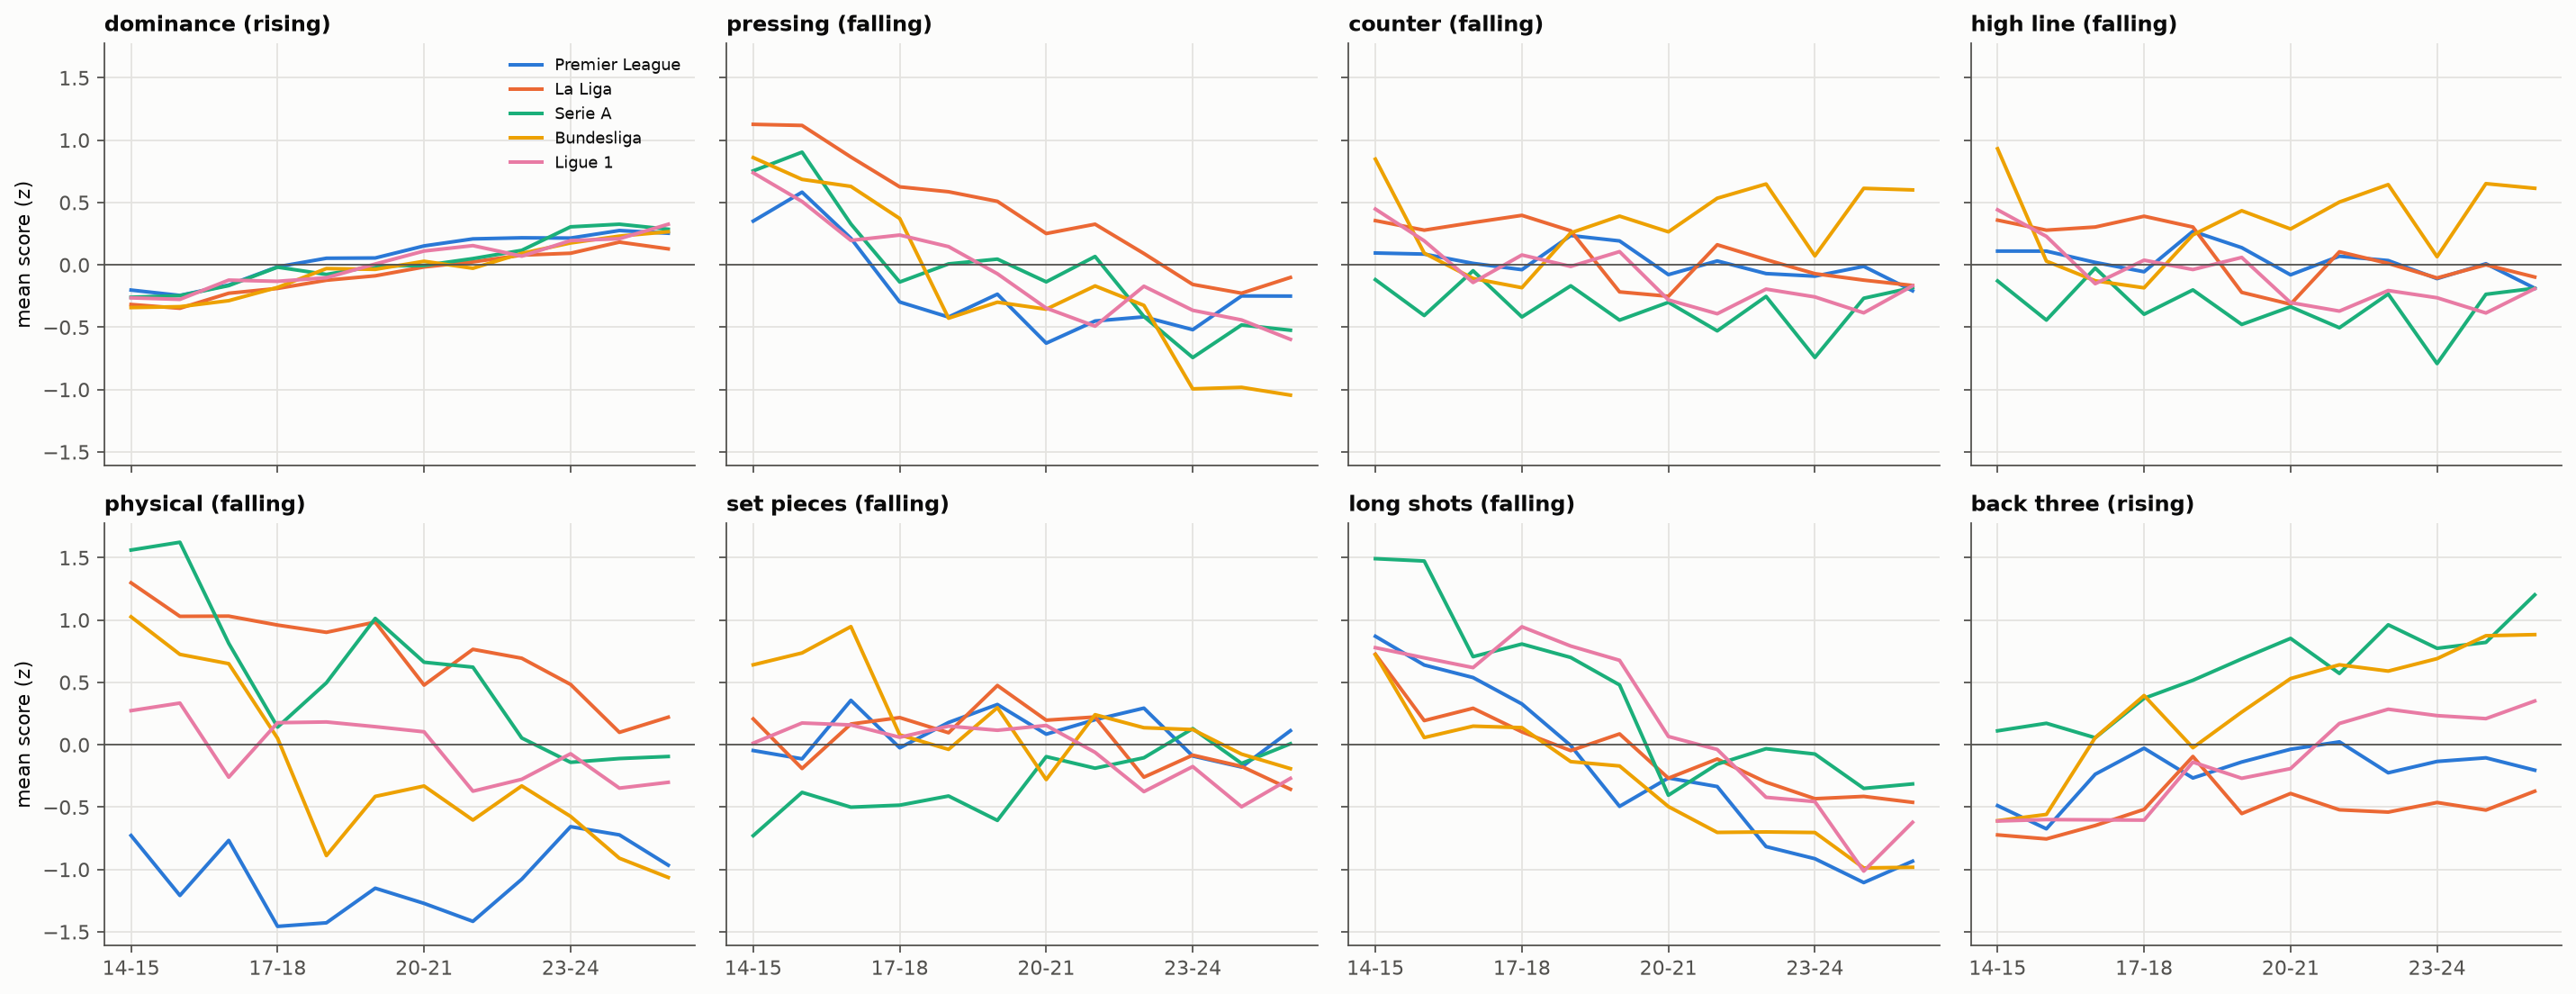

In [20]:
# Figure: each dimension's season mean per league (one panel per dimension, one line per league).
LEAGUE_COLORS = dict(zip(LEAGUES, SERIES))
season_dims = ts.groupby(["season_key", "league"])[DIMS].mean()
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
seasons_x = sorted(ts.season_key.unique())
for ax, d in zip(axes.flat, DIMS):
    for lg in LEAGUES:
        y = season_dims[d].xs(lg, level="league").reindex(seasons_x)
        ax.plot(range(len(y)), y, color=LEAGUE_COLORS[lg], linewidth=1.8, label=lg)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_title(f"{d.replace('_', ' ')} ({shapes.loc[d, 'all leagues']})", loc="left")
    ax.set_xticks(range(0, len(seasons_x), 3), [seasons_x[i][2:] for i in range(0, len(seasons_x), 3)])
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("mean score (z)")
fig.tight_layout()
dims_fig = save(fig, "05_style_dimensions_over_time.png")

## Step 15. How teams move between styles

For every club that played in its Big Five league in two consecutive seasons: its style in season *t* and in *t + 1*.
The diagonal is how often a style is kept; the largest off-diagonal flows are the main routes of change.

In [21]:
nxt = ts[["club_id", "season", "cluster_name"]].assign(season=lambda d: d.season - 1).rename(columns={"cluster_name": "next style"})
moves = ts.merge(nxt, on=["club_id", "season"]).rename(columns={"cluster_name": "style"})
transitions = pd.crosstab(moves["style"], moves["next style"]).loc[STYLE_ORDER, STYLE_ORDER]
transition_share = transitions.div(transitions.sum(axis=1), axis=0)
kept = pd.Series(np.diag(transition_share), index=STYLE_ORDER, name="kept next season")
flows = (transitions.stack().rename("clubs").reset_index().query("style != `next style`")
         .sort_values("clubs", ascending=False).head(8))
kept_by_era = moves.assign(same=moves["style"] == moves["next style"]).groupby("era").same.mean().loc[ERA_ORDER]
print(f"{len(moves):,} consecutive club-season pairs; style kept: {np.trace(transitions.to_numpy()) / transitions.to_numpy().sum():.0%}")
display((100 * transition_share).round(0))
display(kept.round(2).to_frame())
display(kept_by_era.round(2).rename("style kept, by era of the first season").to_frame())
flows

922 consecutive club-season pairs; style kept: 49%


next style,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
style,,,,,,,
Aggressive press and set pieces,48.0,13.0,17.0,4.0,7.0,2.0,10.0
Controlled possession,3.0,48.0,4.0,10.0,7.0,16.0,11.0
Direct and physical,19.0,11.0,42.0,8.0,10.0,1.0,9.0
Back three,6.0,6.0,6.0,59.0,6.0,6.0,13.0
Counter-attacking,8.0,6.0,10.0,11.0,30.0,3.0,32.0
Elite dominance,1.0,26.0,1.0,6.0,2.0,62.0,2.0
Passive low block,6.0,10.0,5.0,12.0,12.0,4.0,52.0


,kept next season
Aggressive press and set pieces,0.48
Controlled possession,0.48
Direct and physical,0.42
Back three,0.59
Counter-attacking,0.30
Elite dominance,0.62
Passive low block,0.52


,"style kept, by era of the first season"
era,
2014–18,0.52
2018–22,0.44
2022–26,0.51


,style,next style,clubs
34,Counter-attacking,Passive low block,29
14,Direct and physical,Aggressive press and set pieces,27
36,Elite dominance,Controlled possession,26
12,Controlled possession,Elite dominance,25
2,Aggressive press and set pieces,Direct and physical,25
1,Aggressive press and set pieces,Controlled possession,19
46,Passive low block,Counter-attacking,18
45,Passive low block,Back three,18


## Step 16. Style mix and injuries per era

The share of team-seasons in each style per era, and each style's injury rate per era as a rate ratio against its
league's **fixed** baseline (the 12-season average), so changes over time stay visible.

In [22]:
mix_era = pd.crosstab(ts.era, ts.cluster_name, normalize="index").loc[ERA_ORDER, STYLE_ORDER]
mix_league_era = pd.crosstab([ts.league, ts.era], ts.cluster_name, normalize="index")[STYLE_ORDER]
era_style = summarise(ps, ["era", "cluster_name"])
rr_era = era_style["RR"].unstack().loc[ERA_ORDER, STYLE_ORDER]
days_era = era_style["days RR"].unstack().loc[ERA_ORDER, STYLE_ORDER]
by_era = summarise(ps, "era").loc[ERA_ORDER]
display((100 * mix_era).round(1))
display(rr_era.round(2))
display(days_era.round(2))
fmt(by_era)

cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
era,,,,,,,
2014–18,25.8,9.4,30.9,4.1,11.7,7.9,10.2
2018–22,13.8,17.3,11.7,15.8,10.5,8.4,22.4
2022–26,6.0,18.1,2.8,22.8,11.7,13.0,25.6


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
era,,,,,,,
2014–18,1.02,1.08,0.93,0.92,0.85,1.17,0.77
2018–22,0.97,1.13,0.86,0.94,0.92,1.28,1.04
2022–26,0.77,1.18,0.61,1.05,0.89,1.27,0.93


cluster_name,Aggressive press and set pieces,Controlled possession,Direct and physical,Back three,Counter-attacking,Elite dominance,Passive low block
era,,,,,,,
2014–18,1.11,1.06,0.96,0.82,0.97,1.02,0.91
2018–22,1.03,0.98,0.95,0.87,0.90,1.01,0.97
2022–26,0.76,1.14,0.72,1.07,1.05,1.18,0.99


,player-seasons,team-seasons,injuries,injuries / player-season,"per 1,000 min",days lost / player-season,severe share,RR (95% CI),days RR (95% CI)
era,,,,,,,,,
2014–18,11949,392,7715,0.646,0.440,30.4,0.458,0.96 (0.92–1.00),1.00 (0.96–1.05)
2018–22,12370,392,8455,0.684,0.492,29.1,0.423,1.02 (0.98–1.06),0.96 (0.91–1.00)
2022–26,12206,386,8411,0.689,0.491,31.9,0.461,1.02 (0.98–1.06),1.05 (1.00–1.09)


## Step 17. How much of the injury trend comes from styles changing?

**Kitagawa decomposition.** The overall rate is the share-weighted sum of the rates in each cell (league × style).
Between two eras, its change splits exactly into:
- **style mix:** the change in each cell's share × its average rate (more players in styles with higher rates);
- **within styles:** the change in each cell's rate × its average share (the same styles getting more or fewer injuries).

Done for injuries, days lost, severe injuries and the two body areas with consistent style patterns (hamstring,
knee), per player-season, for all leagues together and for each league.

In [23]:
OUTCOMES = {"injuries": "injuries", "days lost": "days_lost", "severe injuries": "severe",
            "hamstring injuries": "area: hamstring", "knee injuries": "area: knee"}


def decompose(df: pd.DataFrame, outcome: str, e0: str, e1: str, cells: list[str]) -> dict:
    def table(e):
        d = df[df.era == e]
        t = d.groupby(cells, observed=True).agg(n=(outcome, "size"), rate=(outcome, "mean"))
        return t.assign(w=t.n / t.n.sum())
    a, b = table(e0), table(e1)
    j = a[["w", "rate"]].join(b[["w", "rate"]], how="outer", lsuffix="0", rsuffix="1")
    j[["w0", "w1"]] = j[["w0", "w1"]].fillna(0)
    j["rate0"] = j.rate0.fillna(j.rate1)
    j["rate1"] = j.rate1.fillna(j.rate0)
    total = (j.w1 * j.rate1).sum() - (j.w0 * j.rate0).sum()
    mix = ((j.w1 - j.w0) * (j.rate0 + j.rate1) / 2).sum()
    within = ((j.rate1 - j.rate0) * (j.w0 + j.w1) / 2).sum()
    assert abs(total - mix - within) < 1e-9
    return {"from": (j.w0 * j.rate0).sum(), "to": (j.w1 * j.rate1).sum(), "change": total, "from style mix": mix, "within styles": within}


PAIRS = [(ERA_ORDER[0], ERA_ORDER[1]), (ERA_ORDER[1], ERA_ORDER[2]), (ERA_ORDER[0], ERA_ORDER[2])]
rows = []
for label, col in OUTCOMES.items():
    for e0, e1 in PAIRS:
        rows.append({"outcome": label, "eras": f"{e0} → {e1}", "scope": "all leagues",
                     **decompose(ps, col, e0, e1, ["league", "cluster_name"])})
        for lg in LEAGUES:
            rows.append({"outcome": label, "eras": f"{e0} → {e1}", "scope": lg,
                         **decompose(ps[ps.league == lg], col, e0, e1, ["cluster_name"])})
decomposition = pd.DataFrame(rows)
decomposition["mix share of change"] = decomposition["from style mix"] / decomposition.change
first_last = f"{ERA_ORDER[0]} → {ERA_ORDER[2]}"
display(decomposition[(decomposition.scope == "all leagues")].round(3))
decomposition[(decomposition.eras == first_last) & (decomposition.outcome == "injuries")].round(3)

,outcome,eras,scope,from,to,change,from style mix,within styles,mix share of change
0,injuries,2014–18 → 2018–22,all leagues,0.646,0.684,0.038,0.032,0.005,0.856
6,injuries,2018–22 → 2022–26,all leagues,0.684,0.689,0.006,0.018,-0.013,3.297
12,injuries,2014–18 → 2022–26,all leagues,0.646,0.689,0.043,0.062,-0.019,1.436
18,days lost,2014–18 → 2018–22,all leagues,30.417,29.116,-1.301,-0.867,-0.434,0.667
24,days lost,2018–22 → 2022–26,all leagues,29.116,31.939,2.824,0.552,2.271,0.196
30,days lost,2014–18 → 2022–26,all leagues,30.417,31.939,1.522,1.745,-0.223,1.146
36,severe injuries,2014–18 → 2018–22,all leagues,0.296,0.289,-0.007,-0.006,-0.001,0.913
42,severe injuries,2018–22 → 2022–26,all leagues,0.289,0.318,0.029,0.006,0.022,0.224
48,severe injuries,2014–18 → 2022–26,all leagues,0.296,0.318,0.022,0.019,0.003,0.857
54,hamstring injuries,2014–18 → 2018–22,all leagues,0.083,0.082,-0.001,-0.001,0.000,1.328


,outcome,eras,scope,from,to,change,from style mix,within styles,mix share of change
12,injuries,2014–18 → 2022–26,all leagues,0.646,0.689,0.043,0.062,-0.019,1.436
13,injuries,2014–18 → 2022–26,Premier League,0.559,0.711,0.153,0.041,0.112,0.267
14,injuries,2014–18 → 2022–26,La Liga,0.711,0.486,-0.225,0.128,-0.353,-0.568
15,injuries,2014–18 → 2022–26,Serie A,0.740,0.894,0.154,0.116,0.038,0.756
16,injuries,2014–18 → 2022–26,Bundesliga,0.865,0.743,-0.122,-0.010,-0.112,0.081
17,injuries,2014–18 → 2022–26,Ligue 1,0.375,0.601,0.227,0.014,0.212,0.062


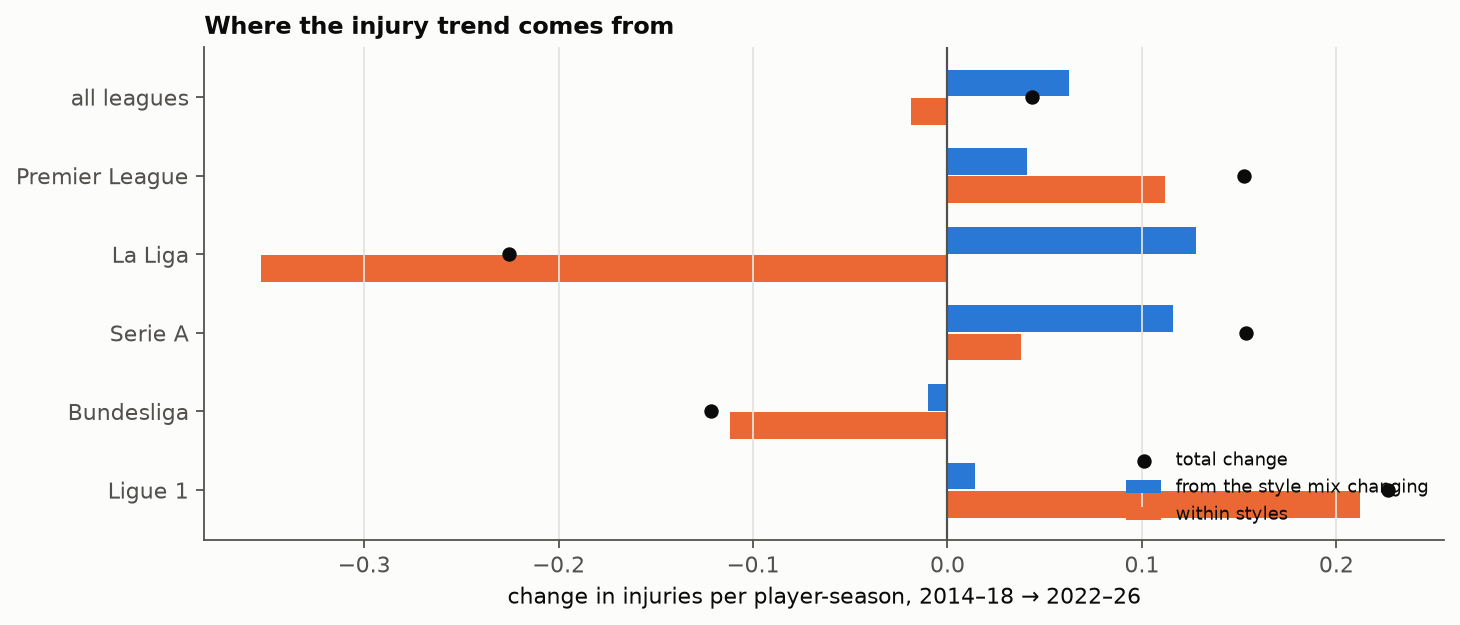

In [24]:
# Figure: change in injuries per player-season, first to last era, split into style mix and within styles.
d = decomposition[(decomposition.eras == first_last) & (decomposition.outcome == "injuries")].set_index("scope").loc[["all leagues"] + LEAGUES]
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(d))[::-1]
ax.barh(y + 0.18, d["from style mix"], height=0.34, color=SERIES[0], label="from the style mix changing")
ax.barh(y - 0.18, d["within styles"], height=0.34, color=SERIES[1], label="within styles")
ax.scatter(d.change, y, color=INK, zorder=3, s=30, label="total change")
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, d.index)
ax.set_xlabel(f"change in injuries per player-season, {first_last}")
ax.set_title("Where the injury trend comes from", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
decomp_fig = save(fig, "05_trend_decomposition.png")

## Step 18. Style dimensions vs injury outcomes across league-seasons

For the 60 league-seasons: the league's average style scores against its injury outcomes. Leagues differ in how
they record injuries, so the correlations are **within league** (both sides centred on the league's own 12-season
mean): they ask whether *a league's seasons with more of a style trait had more of an injury outcome*. Many traits
and injury labels both drift over the 12 seasons, so these level correlations partly repeat a shared time trend
(including recording changes). The stricter version correlates **season-to-season changes** within each league
(n = 55): does a league's injury outcome move in the same season its style moves? Aggregate association only.

In [25]:
ls_dims = ts.groupby(["league", "season_key"])[DIMS].mean()
g = ps.groupby(["league", "season_key"])
known = g.injuries.sum() - g["area: unknown"].sum()
ls_out = pd.DataFrame({
    "injuries / player-season": g.injuries.mean(), "days lost / player-season": g.days_lost.mean(),
    "severe share": g.severe.sum() / g.injuries.sum(),
    "hamstring share": g["area: hamstring"].sum() / known, "knee share": g["area: knee"].sum() / known,
    "muscle share": (g["area: hamstring"].sum() + g["area: unspecified muscle"].sum() + g["area: thigh"].sum()
                     + g["area: calf/achilles/lower leg"].sum()) / known,
})
centred = lambda t: t - t.groupby(level="league").transform("mean")
cd, co = centred(ls_dims), centred(ls_out)
link = pd.DataFrame({o: {d: cd[d].corr(co[o]) for d in DIMS} for o in co.columns}).round(2)
changes = lambda t: t.groupby(level="league").diff().dropna()
dd, do = changes(ls_dims.sort_index()), changes(ls_out.sort_index())
link_changes = pd.DataFrame({o: {d: dd[d].corr(do[o]) for d in DIMS} for o in do.columns}).round(2)
strongest = link.abs().stack().sort_values(ascending=False).head(6)
display(link)
display(strongest.rename("|r|").to_frame())
link_changes

,injuries / player-season,days lost / player-season,severe share,hamstring share,knee share,muscle share
dominance,0.15,0.04,-0.09,0.05,-0.57,0.59
pressing,-0.09,0.04,0.10,-0.06,0.51,-0.49
counter,-0.06,-0.02,0.03,0.20,0.16,-0.21
high_line,-0.06,-0.02,0.05,0.20,0.18,-0.20
physical,-0.04,0.14,0.11,-0.14,0.41,-0.40
set_pieces,0.11,0.13,-0.07,-0.17,0.11,-0.34
long_shots,-0.29,-0.19,0.13,-0.08,0.56,-0.63
back_three,0.23,0.07,-0.14,0.10,-0.59,0.51


|r|
long_shots muscle share  0.63
back_three knee share    0.59
dominance  muscle share  0.59
           knee share    0.57
long_shots knee share    0.56
back_three muscle share  0.51

,injuries / player-season,days lost / player-season,severe share,hamstring share,knee share,muscle share
dominance,0.00,-0.16,-0.04,-0.19,-0.25,0.02
pressing,0.01,0.10,0.01,0.01,0.08,0.01
counter,0.11,0.15,0.04,-0.05,0.02,-0.10
high_line,0.12,0.14,0.04,-0.05,0.05,-0.14
physical,0.06,0.23,0.04,0.07,-0.03,-0.12
set_pieces,0.02,-0.10,-0.01,-0.12,-0.08,-0.29
long_shots,-0.15,-0.23,-0.07,0.06,-0.04,-0.18
back_three,0.00,0.01,0.02,0.20,-0.23,0.02


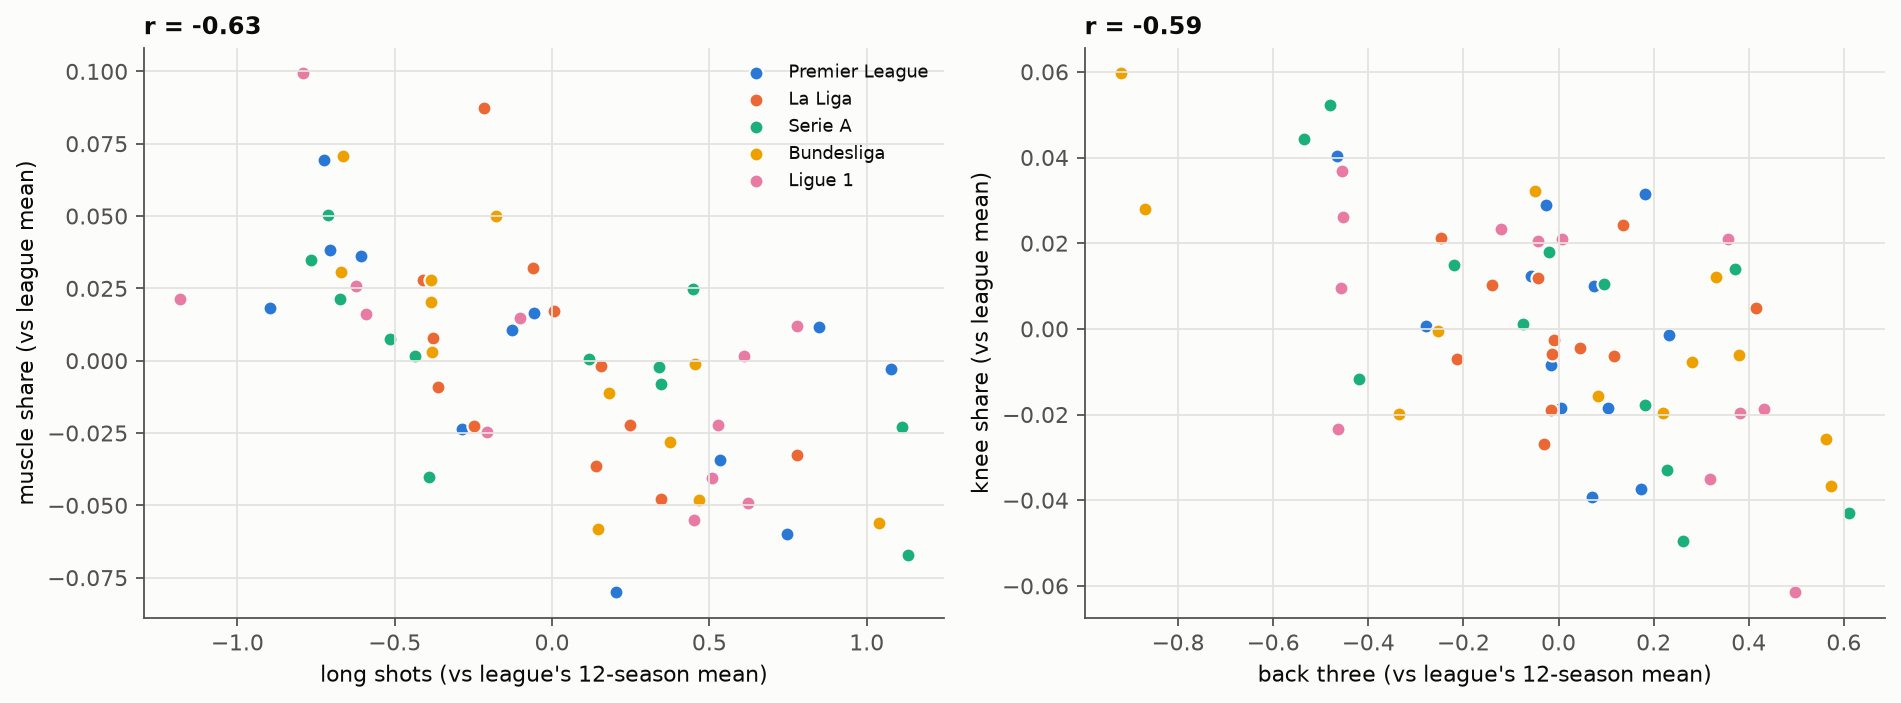

In [26]:
# Figure: the two strongest within-league links as scatter plots (each dot a league-season, coloured by league).
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (d, o) in zip(axes, strongest.index[:2]):
    for lg in LEAGUES:
        ax.scatter(cd.xs(lg, level="league")[d], co.xs(lg, level="league")[o], color=LEAGUE_COLORS[lg], s=40,
                   edgecolors=SURFACE, linewidths=1, label=lg)
    ax.set_xlabel(f"{d.replace('_', ' ')} (vs league's 12-season mean)")
    ax.set_ylabel(f"{o} (vs league mean)")
    ax.set_title(f"r = {link.loc[d, o]:+.2f}", loc="left")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
link_fig = save(fig, "05_style_injury_links.png")

## Step 19. One story per league

Each league's evolution in a few sentences, assembled from steps 14–17: which styles grew and shrank, which ways of
playing changed and how, and what happened to injuries, split into the part from the style mix and the part within
styles.

In [27]:
def pct_pts(x: float) -> str:
    return f"{100 * x:+.0f} pts"


stories = {}
first, last = ERA_ORDER[0], ERA_ORDER[2]
for lg in LEAGUES:
    m = mix_league_era.loc[lg]
    change = (m.loc[last] - m.loc[first]).sort_values()
    grew = [f"{s} ({100 * m.loc[first, s]:.0f}% → {100 * m.loc[last, s]:.0f}%)" for s in change.index[::-1][:2] if change[s] > 0.02]
    shrank = [f"{s} ({100 * m.loc[first, s]:.0f}% → {100 * m.loc[last, s]:.0f}%)" for s in change.index[:2] if change[s] < -0.02]
    moved = [f"{d.replace('_', ' ')} {shapes.loc[d, lg]}" for d in DIMS if shapes.loc[d, lg] != "flat"]
    dec = decomposition[(decomposition.scope == lg) & (decomposition.eras == first_last)].set_index("outcome")
    inj, days = dec.loc["injuries"], dec.loc["days lost"]
    ham, knee = dec.loc["hamstring injuries"], dec.loc["knee injuries"]
    stories[lg] = (
        f"**{lg}.** From {first} to {last}, " + (", ".join(grew) + " grew" if grew else "no style grew much")
        + ("; " + ", ".join(shrank) + " shrank" if shrank else "") + ". "
        + (f"Ways of playing: {', '.join(moved)}. " if moved else "")
        + f"Injuries per player-season went from {inj['from']:.2f} to {inj['to']:.2f} ({inj.change:+.2f}): "
        f"{inj['from style mix']:+.3f} from the style mix, {inj['within styles']:+.3f} within styles. "
        f"Days lost per player-season {days['from']:.1f} → {days['to']:.1f}; hamstring injuries per player-season "
        f"{ham['from']:.3f} → {ham['to']:.3f} (style mix {ham['from style mix']:+.3f}); knee {knee['from']:.3f} → {knee['to']:.3f} "
        f"(style mix {knee['from style mix']:+.3f})."
    )
for s in stories.values():
    display(Markdown(s))

**Premier League.** From 2014–18 to 2022–26, Passive low block (30% → 38%), Back three (4% → 11%) grew; Direct and physical (18% → 0%), Counter-attacking (12% → 5%) shrank. Ways of playing: dominance rising, pressing falling, counter falling, high line falling, physical dip, set pieces peak, long shots falling, back three rising. Injuries per player-season went from 0.56 to 0.71 (+0.15): +0.041 from the style mix, +0.112 within styles. Days lost per player-season 34.4 → 38.7; hamstring injuries per player-season 0.114 → 0.139 (style mix +0.004); knee 0.113 → 0.110 (style mix +0.003).

**La Liga.** From 2014–18 to 2022–26, Passive low block (1% → 25%), Controlled possession (9% → 26%) grew; Aggressive press and set pieces (48% → 18%), Direct and physical (24% → 8%) shrank. Ways of playing: dominance rising, pressing falling, counter falling, high line falling, physical falling, set pieces peak, long shots falling, back three rising. Injuries per player-season went from 0.71 to 0.49 (-0.23): +0.128 from the style mix, -0.353 within styles. Days lost per player-season 30.8 → 23.8; hamstring injuries per player-season 0.118 → 0.087 (style mix +0.014); knee 0.101 → 0.064 (style mix +0.014).

**Serie A.** From 2014–18 to 2022–26, Back three (12% → 49%), Passive low block (0% → 15%) grew; Direct and physical (59% → 5%), Counter-attacking (10% → 8%) shrank. Ways of playing: dominance rising, pressing falling, counter falling, high line falling, physical falling, set pieces rising, long shots falling, back three rising. Injuries per player-season went from 0.74 to 0.89 (+0.15): +0.116 from the style mix, +0.038 within styles. Days lost per player-season 27.1 → 35.0; hamstring injuries per player-season 0.083 → 0.133 (style mix +0.024); knee 0.104 → 0.098 (style mix +0.004).

**Bundesliga.** From 2014–18 to 2022–26, Back three (4% → 28%), Passive low block (12% → 29%) grew; Aggressive press and set pieces (47% → 4%), Direct and physical (15% → 0%) shrank. Ways of playing: dominance rising, pressing falling, counter rising, high line rising, physical falling, set pieces falling, long shots falling, back three rising. Injuries per player-season went from 0.86 to 0.74 (-0.12): -0.010 from the style mix, -0.112 within styles. Days lost per player-season 42.5 → 35.8; hamstring injuries per player-season 0.034 → 0.060 (style mix +0.009); knee 0.151 → 0.111 (style mix -0.027).

**Ligue 1.** From 2014–18 to 2022–26, Back three (0% → 22%), Controlled possession (9% → 23%) grew; Direct and physical (38% → 1%), Aggressive press and set pieces (28% → 3%) shrank. Ways of playing: dominance rising, pressing falling, counter falling, high line falling, physical falling, set pieces falling, long shots falling, back three rising. Injuries per player-season went from 0.37 to 0.60 (+0.23): +0.014 from the style mix, +0.212 within styles. Days lost per player-season 18.4 → 26.2; hamstring injuries per player-season 0.059 → 0.079 (style mix -0.012); knee 0.060 → 0.086 (style mix +0.008).

## Step 20. Report

In [28]:
sig = by_style[(by_style["RR low"] > 1) | (by_style["RR high"] < 1)]
sig_days = by_style[(by_style["days RR low"] > 1) | (by_style["days RR high"] < 1)]
cols = ["player-seasons", "team-seasons", "injuries", "injuries / player-season", "per 1,000 min", "days lost / player-season",
        "severe share", "RR (95% CI)", "days RR (95% CI)"]
text = [
    "# Phase 5: Injury analysis",
    "",
    f"Generated {date.today().isoformat()} by `notebooks/05_injury_analysis.ipynb`, where each step is shown with its checks.",
    "",
    "## Key numbers",
    "",
    f"- {len(ps):,} player-club-seasons, {int(ps.injuries.sum()):,} injuries > 7 days, {int(ps.days_lost.sum()):,} days lost.",
    f"- Styles whose injury RR CI excludes 1: " + (", ".join(f"{s} {r:.2f}" for s, r in sig["RR"].items()) or "none") + ".",
    f"- Styles whose days-lost RR CI excludes 1: " + (", ".join(f"{s} {r:.2f}" for s, r in sig_days["days RR"].items()) or "none") + ".",
    f"- Observed vs expected injuries across styles: chi² = {style_test[0]:.1f}, df = {style_test[1]}, p = {style_test[2]:.2g}.",
    f"- Body-area mix by style: chi² = {chi:.1f}, df = {dof_area}, p = {p_area:.2g}, Cramér's V = {cramers_v:.3f}.",
    f"- Same direction in every sensitivity check: {', '.join(direction[direction].index) or 'none'}.",
    "",
    "## 1. Injuries by style (k = 7)",
    "",
    md_table(fmt(by_style)[cols].rename_axis("style")),
    "",
    f"![Rates by style](figures/{style_fig})",
    "",
    "## 2. Body areas by style",
    "",
    md_table((100 * area_share).round(1).rename_axis("style")),
    "",
    "Standardised residuals (known areas):",
    "",
    md_table(residuals.round(1).rename_axis("style")),
    "",
    f"![Body areas](figures/{area_fig})",
    "",
    "Within each league (style's share relative to its league's share; median over leagues, and leagues above 1):",
    "",
    md_table(median_rel.rename_axis("style")),
    "",
    md_table(leagues_above.rename_axis("style")),
    "",
    "## 3. Seasons",
    "",
    md_table(fmt(by_season)[["player-seasons", "injuries / player-season", "days lost / player-season", "severe share"]].join(unknown_share.round(3)).rename_axis("season")),
    "",
    f"![Season trend](figures/{trend_fig})",
    "",
    f"![Style shares](figures/{shares_fig})",
    "",
    "## 4. Leagues",
    "",
    md_table(fmt(by_league)[cols].rename_axis("league")),
    "",
    "Style RR within each league:",
    "",
    md_table(rr_within.round(2).rename_axis("league")),
    "",
    f"![Within league](figures/{league_fig})",
    "",
    "## 5. Age and position",
    "",
    md_table(compare.join(mix).rename_axis("style")),
    "",
    "## 6. Team strength and workload",
    "",
    "Style RR within thirds of team strength (points per match):",
    "",
    md_table(rr_strength.round(2).rename_axis("strength")),
    "",
    "By congestion (share of matches on < 4 days' rest, thirds over player-seasons):",
    "",
    md_table(fmt(by_congestion)[cols].rename_axis("congestion")),
    "",
    "## 7. Fitness absences (Bundesliga, secondary outcome)",
    "",
    md_table(fitness.loc[STYLE_ORDER].rename_axis("style")),
    "",
    "## 8. Sensitivity checks (injury RR by style)",
    "",
    md_table(sensitivity.rename_axis("variant")),
    "",
    "k = 4 robustness check:",
    "",
    md_table(fmt(k4)[cols].rename_axis("style (k = 4)")),
    "",
    "## 9. Style cards (core team-seasons)",
    "",
    *[f"- **{name}** ({c['family (k = 4)']} family; {c['team-seasons']} team-seasons, core {c['core']}): {c['how it plays']}. "
      f"{c['in numbers (core)']}. Points/match {c['points/match']}, European matches {c['European matches']}. "
      f"Typical: {c['typical 2014–18']} | {c['typical 2018–22']} | {c['typical 2022–26']}." for name, c in cards.iterrows()],
    "",
    "Injury RR, all teams vs core teams only:",
    "",
    md_table(core_check.rename_axis("style")),
    "",
    "## 10. How the ways of playing changed",
    "",
    md_table(era_all.T.round(2).assign(shape=shapes["all leagues"]).rename_axis("dimension (z)")),
    "",
    "Shape per league:",
    "",
    md_table(shapes.rename_axis("dimension")),
    "",
    "In real units (all leagues):",
    "",
    md_table(raw_by_era.round(3).rename_axis("measure")),
    "",
    f"![Dimensions over time](figures/{dims_fig})",
    "",
    "## 11. How teams move between styles",
    "",
    md_table((100 * transition_share).round(0).rename_axis("style \u2192 next season")),
    "",
    "Largest moves between styles:",
    "",
    md_table(flows, index=False),
    "",
    "## 12. Style mix and injuries per era",
    "",
    md_table((100 * mix_era).round(1).rename_axis("era")),
    "",
    "Injury RR per style and era (fixed league baselines):",
    "",
    md_table(rr_era.round(2).rename_axis("era")),
    "",
    "## 13. Where the injury trend comes from (Kitagawa decomposition)",
    "",
    md_table(decomposition[decomposition.scope == "all leagues"].drop(columns="scope").round(3), index=False),
    "",
    f"![Decomposition](figures/{decomp_fig})",
    "",
    "## 14. Style dimensions vs injury outcomes (within-league correlations, 60 league-seasons)",
    "",
    md_table(link.rename_axis("dimension")),
    "",
    "Season-to-season changes (within league, n = 55; removes slow shared trends):",
    "",
    md_table(link_changes.rename_axis("dimension")),
    "",
    f"![Links](figures/{link_fig})",
    "",
    "## 15. One story per league",
    "",
    *[f"{story}\n" for story in stories.values()],
    "",
    "## 16. Outputs",
    "",
    f"- `data/{PHASE}/player_seasons.parquet`: the player-club-season table with style, strength, workload, age, position and injuries.",
    "",
]
(REPORTS_DIR / "05_injury_analysis.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "05_injury_analysis.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/05_injury_analysis.md
